In [24]:
import importlib.util
import os
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

PROJECT_DIRECTORY = Path(r'C:\clg').resolve()
ARTIFACT_DIRECTORY = PROJECT_DIRECTORY / 'skin_pipeline_artifacts'
CACHE_DIRECTORY = PROJECT_DIRECTORY / '.cache'
TEMP_DIRECTORY = PROJECT_DIRECTORY / '.tmp'
for directory in (PROJECT_DIRECTORY, ARTIFACT_DIRECTORY, CACHE_DIRECTORY, TEMP_DIRECTORY):
    directory.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_DIRECTORY)
os.environ['SKIN_PIPELINE_ROOT'] = str(ARTIFACT_DIRECTORY)
os.environ['KAGGLE_CONFIG_DIR'] = str(PROJECT_DIRECTORY)
os.environ['TORCH_HOME'] = str(CACHE_DIRECTORY / 'torch')
os.environ['HF_HOME'] = str(CACHE_DIRECTORY / 'huggingface')
os.environ['HF_HUB_CACHE'] = str(CACHE_DIRECTORY / 'huggingface' / 'hub')
os.environ['HUGGINGFACE_HUB_CACHE'] = os.environ['HF_HUB_CACHE']
os.environ['XDG_CACHE_HOME'] = str(CACHE_DIRECTORY)
os.environ['MPLCONFIGDIR'] = str(CACHE_DIRECTORY / 'matplotlib')
os.environ['PIP_CACHE_DIR'] = str(CACHE_DIRECTORY / 'pip')
for variable in ('TEMP', 'TMP', 'TMPDIR'):
    os.environ[variable] = str(TEMP_DIRECTORY)
tempfile.tempdir = str(TEMP_DIRECTORY)

if 'huggingface_hub.constants' in sys.modules:
    hub_constants = sys.modules['huggingface_hub.constants']
    hub_constants.HF_HOME = os.environ['HF_HOME']
    hub_constants.HF_HUB_CACHE = os.environ['HF_HUB_CACHE']
    hub_constants.HUGGINGFACE_HUB_CACHE = os.environ['HF_HUB_CACHE']

local_hub = Path(os.environ['HF_HUB_CACHE'])
local_hub.mkdir(parents=True, exist_ok=True)
previous_hub = Path.home() / '.cache' / 'huggingface' / 'hub'
for repository in ('models--timm--mobilenetv3_large_100.ra_in1k', 'models--timm--mobilenetv4_conv_small.e2400_r224_in1k', 'models--timm--lcnet_100.ra2_in1k'):
    previous = previous_hub / repository
    destination = local_hub / repository
    if previous.is_dir() and not destination.exists():
        shutil.move(str(previous), str(destination))
        print('Relocated requested pretrained model cache:', destination)

if sys.platform == 'win32':
    if importlib.util.find_spec('truststore') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'truststore>=0.10,<1'])
    import truststore
    truststore.inject_into_ssl()
    print('HTTPS certificate verification enabled using the Windows trusted certificate store.')

print('Working directory:', PROJECT_DIRECTORY)
print('Kaggle credential location:', PROJECT_DIRECTORY / 'kaggle.json')
print('Dataset/runtime/checkpoint/report storage:', ARTIFACT_DIRECTORY)
print('Caches:', CACHE_DIRECTORY)
print('Temporary files:', TEMP_DIRECTORY)
print('Run this path/TLS cell before Setup and after any kernel restart. Keep USE_GOOGLE_DRIVE=False for this local-only run.')

Relocated requested pretrained model cache: C:\clg\.cache\huggingface\hub\models--timm--mobilenetv3_large_100.ra_in1k
Relocated requested pretrained model cache: C:\clg\.cache\huggingface\hub\models--timm--mobilenetv4_conv_small.e2400_r224_in1k
Relocated requested pretrained model cache: C:\clg\.cache\huggingface\hub\models--timm--lcnet_100.ra2_in1k
HTTPS certificate verification enabled using the Windows trusted certificate store.
Working directory: C:\clg
Kaggle credential location: C:\clg\kaggle.json
Dataset/runtime/checkpoint/report storage: C:\clg\skin_pipeline_artifacts
Caches: C:\clg\.cache
Temporary files: C:\clg\.tmp
Run this path/TLS cell before Setup and after any kernel restart. Keep USE_GOOGLE_DRIVE=False for this local-only run.


In [6]:
import ast
import importlib.util
import json
import os
import subprocess
import sys
from pathlib import Path

DEMO_MODE = True
USE_GOOGLE_DRIVE = False
INSTALL_DEPENDENCIES = True
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ['SKIN_PIPELINE_ROOT'] = '/content/drive/MyDrive/skin_pipeline_artifacts'
ROOT = Path(os.environ.get('SKIN_PIPELINE_ROOT', '/content/skin_pipeline_artifacts' if Path('/content').exists() else str(Path.home() / 'skin_pipeline_artifacts'))).resolve()
ROOT.mkdir(parents=True, exist_ok=True)
requirements = {'torch': 'torch', 'torchvision': 'torchvision', 'timm': 'timm==1.0.15', 'pandas': 'pandas', 'numpy': 'numpy', 'sklearn': 'scikit-learn', 'PIL': 'Pillow', 'matplotlib': 'matplotlib', 'kaggle': 'kaggle==1.6.17', 'pytorch_grad_cam': 'grad-cam==1.5.5', 'google.generativeai': 'google-generativeai==0.8.5'}
missing = []
for module, package in requirements.items():
    try:
        found = importlib.util.find_spec(module)
    except ModuleNotFoundError:
        found = None
    if found is None:
        missing.append(package)
if missing:
    if not INSTALL_DEPENDENCIES:
        raise RuntimeError('Missing packages: ' + ', '.join(missing) + '. Enable INSTALL_DEPENDENCIES in Setup.')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

CONFIG = {
    'demo': DEMO_MODE, 'seed': 42, 'image_size': 64 if DEMO_MODE else 224,
    'epochs': 2 if DEMO_MODE else 20, 'batch_size': 8 if DEMO_MODE else 32,
    'samples_per_class': 2 if DEMO_MODE else None, 'pretrained': not DEMO_MODE,
    'mc_passes': 4 if DEMO_MODE else 30, 'latency_repeats': 3 if DEMO_MODE else 30,
    'dropout': 0.3, 'lr': 0.001 if DEMO_MODE else 0.0001,
    'primary_dataset': 'HAM10000', 'acne_confirmed': False, 'report_image': None,
    'local_roots': {'HAM10000': None, 'PAD_UFES_20': None, 'ACNE04': None},
    'slugs': {'HAM10000': 'kmader/skin-cancer-mnist-ham10000', 'PAD_UFES_20': 'mahdavi1202/skin-cancer', 'ACNE04': 'jincyjis/acne04'},
    'severity_label_base': 1, 'expert_sample_size': 10,
}
RUNTIME_SOURCE = r'''
import copy
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import zipfile
from contextlib import nullcontext
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision.transforms as transforms
import timm
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold

MODELS = ('mobilenetv3_small_100', 'mobilenetv2_100', 'efficientnet_b0', 'tf_efficientnet_lite0', 'ghostnet_100', 'mobilevit_xxs')
DISPLAY = ('MobileNetV3-Small', 'MobileNetV2', 'EfficientNet-B0', 'EfficientNet-Lite0', 'GhostNet-1.0', 'MobileViT-XXS')
TAXONOMY = {'akiec': 'actinic_keratosis_or_intraepithelial_carcinoma', 'bcc': 'basal_cell_carcinoma', 'bkl': 'benign_keratosis', 'df': 'dermatofibroma', 'mel': 'melanoma', 'nv': 'nevus', 'nev': 'nevus', 'vasc': 'vascular_lesion', 'ack': 'actinic_keratosis', 'scc': 'squamous_cell_carcinoma', 'sek': 'seborrheic_keratosis'}
SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp'}
GRADE_PATTERN = re.compile(r'(?:levle|level|grade|severity)[ _-]*([1-4])(?:[ _.-]|$)', re.I)


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def read_json(path, instruction):
    path = Path(path)
    if not path.exists():
        raise RuntimeError(f'Missing artifact {path}. {instruction}. If Colab deleted its disk, mount the same Drive root and rerun Setup.')
    return json.loads(path.read_text(encoding='utf-8'))


def grade_from_filename(path):
    match = GRADE_PATTERN.search(Path(path).name)
    return int(match.group(1)) if match else None


def metrics(truth, predicted, classes):
    precision, recall, f1, _ = precision_recall_fscore_support(truth, predicted, labels=list(range(len(classes))), average='macro', zero_division=0)
    return {'Precision': float(precision), 'Recall': float(recall), 'Accuracy': float(accuracy_score(truth, predicted)), 'F1': float(f1), 'Confusion': confusion_matrix(truth, predicted, labels=list(range(len(classes)))).tolist()}


class ImageDataset(Dataset):
    def __init__(self, frame, classes, size, training=False):
        self.frame = frame.reset_index(drop=True)
        self.lookup = {label: index for index, label in enumerate(classes)}
        operations = [transforms.Resize((size, size))]
        if training:
            operations += [transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)]
        operations += [transforms.ToTensor(), transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))]
        self.transform = transforms.Compose(operations)
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['path']) as image:
            tensor = self.transform(image.convert('RGB'))
        return tensor, self.lookup[str(row['label'])]


class CBAM(nn.Module):
    def __init__(self, channels, reduction=32):
        super().__init__()
        hidden = max(1, channels // reduction)
        self.channel_mlp = nn.Sequential(nn.Conv2d(channels, hidden, 1, bias=False), nn.ReLU(), nn.Conv2d(hidden, channels, 1, bias=False))
        self.spatial = nn.Conv2d(2, 1, 7, padding=3, bias=False)
    def forward(self, features):
        channel = torch.sigmoid(self.channel_mlp(features.mean((2, 3), keepdim=True)) + self.channel_mlp(features.amax((2, 3), keepdim=True)))
        features = features * channel
        spatial = torch.sigmoid(self.spatial(torch.cat([features.mean(1, keepdim=True), features.amax(1, keepdim=True)], dim=1)))
        return features * spatial


class DualHead(nn.Module):
    def __init__(self, backbone, channels, disease_classes, dropout):
        super().__init__()
        self.backbone = backbone
        self.cbam = CBAM(channels)
        self.dropout = nn.Dropout(dropout)
        self.disease_head = nn.Linear(channels, disease_classes)
        self.severity_head = nn.Linear(channels, 4)
    def forward_cached(self, features):
        if features.ndim != 4:
            raise RuntimeError(f'CBAM requires NCHW spatial features, received {tuple(features.shape)}')
        pooled = self.dropout(self.cbam(features).mean((2, 3)))
        return {'disease': self.disease_head(pooled), 'severity': self.severity_head(pooled)}
    def forward(self, images):
        return self.forward_cached(self.backbone.forward_features(images))


class TaskView(nn.Module):
    def __init__(self, model, task):
        super().__init__()
        self.model, self.task = model, task
    def forward(self, images):
        return self.model(images)[self.task]


class Pipeline:
    def __init__(self, root):
        self.root = Path(root).resolve()
        self.cfg = read_json(self.root / 'config.json', 'Run Setup')
        self.run = self.root / ('demo' if self.cfg['demo'] else 'full')
        self.run.mkdir(parents=True, exist_ok=True)
        self.device = torch.device('cpu' if self.cfg['demo'] else ('cuda' if torch.cuda.is_available() else 'cpu'))
        self.seed()
        torch.set_num_threads(min(4, os.cpu_count() or 1))
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True, warn_only=True)
        self.signature = hashlib.sha256(json.dumps(self.cfg, sort_keys=True).encode()).hexdigest()
        marker = self.run / 'run_config.json'
        if marker.exists() and read_json(marker, 'Run Setup')['signature'] != self.signature:
            raise RuntimeError(f'Configuration changed for {self.run}. Use a new SKIN_PIPELINE_ROOT or explicitly archive this mode directory before rerunning. Stale checkpoints are not reused.')
        write_json(marker, {'signature': self.signature, 'config': self.cfg, 'versions': {'torch': torch.__version__, 'timm': timm.__version__}})
    def seed(self):
        random.seed(self.cfg['seed'])
        np.random.seed(self.cfg['seed'])
        torch.manual_seed(self.cfg['seed'])
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(self.cfg['seed'])
    def preflight(self):
        if not os.environ.get('GEMINI_API_KEY'):
            raise RuntimeError('Missing GEMINI_API_KEY. Get a key at https://aistudio.google.com/apikey and put it in Colab Secrets or your environment; never paste it into notebook outputs.')
        needs_kaggle = any(not self.cfg['local_roots'].get(name) for name in self.cfg['slugs'])
        if needs_kaggle:
            credentials = Path(os.environ.get('KAGGLE_CONFIG_DIR', str(Path.home() / '.kaggle'))) / 'kaggle.json'
            env_auth = bool(os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'))
            if not credentials.exists() and not env_auth:
                raise RuntimeError('Missing Kaggle credentials: place kaggle.json in ~/.kaggle/ or set KAGGLE_USERNAME and KAGGLE_KEY. Obtain them at https://www.kaggle.com/settings/account (API). Alternatively set all three local_roots in Setup.')
        print('Credential presence checked (values are not printed). API authorization/quota is checked by the actual request.')
    def safe_extract(self, archive, destination):
        destination = Path(destination).resolve()
        destination.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as bundle:
            broken = bundle.testzip()
            if broken:
                raise zipfile.BadZipFile(f'CRC failure: {broken}')
            for member in bundle.infolist():
                target = (destination / member.filename).resolve()
                if not target.is_relative_to(destination) or ((member.external_attr >> 16) & 0o170000) == 0o120000:
                    raise ValueError(f'Unsafe archive member: {member.filename}')
            bundle.extractall(destination)
    def images(self, directory):
        return sorted(path for path in Path(directory).rglob('*') if path.suffix.lower() in SUFFIXES)
    def parse_disease(self, name, directory):
        paths = self.images(directory)
        by_name, by_stem = {}, {}
        for path in paths:
            by_name.setdefault(path.name.lower(), []).append(path)
            by_stem.setdefault(path.stem.lower(), []).append(path)
        for csv in sorted(Path(directory).rglob('*.csv')):
            try:
                frame = pd.read_csv(csv)
            except (ValueError, UnicodeError, pd.errors.ParserError):
                continue
            frame.columns = [str(column).strip().lower() for column in frame.columns]
            required = ('image_id', 'dx') if name == 'HAM10000' else ('img_id', 'diagnostic')
            if not set(required).issubset(frame.columns):
                continue
            group_column = 'lesion_id' if name == 'HAM10000' else 'patient_id'
            if group_column not in frame or frame[group_column].isna().any():
                raise ValueError(f'{csv}: missing {group_column}. Group-disjoint splitting needs lesion identifiers for HAM10000 and patient identifiers for PAD-UFES-20; use the original metadata mirror.')
            records, missing = [], []
            for _, row in frame.iterrows():
                identifier = str(row[required[0]]).replace('\\', '/').split('/')[-1].lower()
                candidates = by_name.get(identifier, by_stem.get(Path(identifier).stem, []))
                if not candidates:
                    missing.append(identifier)
                    continue
                label = str(row[required[1]]).strip().lower()
                if label not in TAXONOMY:
                    raise ValueError(f'Unknown disease label {label!r} in {csv}; supply an explicit taxonomy mapping, never guess a column or class.')
                path = candidates[0]
                if len(candidates) > 1:
                    hashes = {hashlib.sha256(item.read_bytes()).hexdigest() for item in candidates}
                    if len(hashes) != 1:
                        raise ValueError(f'Ambiguous image identifier {identifier}: multiple different images.')
                records.append({'path': str(path.resolve()), 'label': TAXONOMY[label], 'group': str(row[group_column])})
            if missing:
                raise ValueError(f'{csv}: {len(missing)} metadata images missing, examples {missing[:3]}. Re-extract or redownload.')
            if not records:
                raise ValueError(f'No matching images for {csv}')
            return pd.DataFrame(records)
        raise ValueError(f'No compatible metadata CSV under {directory}. Required columns: {required if paths else ("image_id/dx or img_id/diagnostic")}; images found: {len(paths)}.')
    def parse_acne(self, directory):
        paths = self.images(directory)
        fallback = {}
        for csv in sorted(Path(directory).rglob('*.csv')):
            try:
                frame = pd.read_csv(csv)
            except (ValueError, UnicodeError):
                continue
            frame.columns = [str(column).strip().lower() for column in frame.columns]
            image_column = next((column for column in ('filename', 'image', 'image_id', 'img_id', 'path') if column in frame), None)
            grade_column = next((column for column in ('grade', 'severity', 'level', 'label') if column in frame), None)
            if image_column and grade_column:
                for _, row in frame.iterrows():
                    fallback[Path(str(row[image_column])).stem] = row[grade_column]
        for annotation in sorted(Path(directory).rglob('*.txt')):
            for line in annotation.read_text(encoding='utf-8', errors='replace').splitlines():
                match = re.fullmatch(r'\s*(\S+\.(?:jpg|jpeg|png))\s*[,;\t ]+([0-4])\s*', line, re.I)
                if match:
                    fallback.setdefault(Path(match.group(1)).stem, match.group(2))
        records, unresolved = [], []
        for path in paths:
            grade = grade_from_filename(path)
            source = 'filename'
            if grade is None and path.stem in fallback:
                raw = fallback[path.stem]
                encoded = GRADE_PATTERN.search(str(raw) + '_')
                try:
                    grade = int(encoded.group(1)) if encoded else int(float(raw)) + (1 if self.cfg['severity_label_base'] == 0 else 0)
                    source = 'csv_or_txt'
                except (ValueError, TypeError):
                    grade = None
            if grade is None:
                for parent in path.parents:
                    if parent == Path(directory).parent:
                        break
                    match = GRADE_PATTERN.search(parent.name + '_')
                    if match:
                        grade, source = int(match.group(1)), 'folder'
                        break
                    if parent.name in ('0', '1', '2', '3', '4'):
                        grade = int(parent.name) + (1 if self.cfg['severity_label_base'] == 0 else 0)
                        source = 'folder'
                        break
            if grade not in (1, 2, 3, 4):
                unresolved.append(str(path))
                continue
            group = re.sub(r'(?i)(?:levle|level|grade|severity)[ _-]*[1-4][ _-]*', '', path.stem)
            sidecar = path.with_suffix('.txt')
            if source != 'filename' and sidecar.exists() and grade is None:
                raise ValueError('Unresolved sidecar grade; bounding-box counts are not automatically converted into clinical grades.')
            records.append({'path': str(path.resolve()), 'label': f'grade_{grade}', 'group': group, 'label_source': source})
        if unresolved or not records:
            raise ValueError(f'ACNE04 unresolved severity labels for {len(unresolved)} images; examples: {unresolved[:3]}. Expected levle1_*.jpg through levle4_*.jpg; fallback CSV/folder/filename-grade text only. Do not guess grades from lesion counts.')
        result = pd.DataFrame(records)
        if set(result['label']) != {'grade_1', 'grade_2', 'grade_3', 'grade_4'}:
            raise ValueError('ACNE04 must contain all four grades; verify the mirror/extraction and severity_label_base.')
        print('ACNE04 label sources:', result['label_source'].value_counts().to_dict())
        return result
    def discover(self, name):
        local = self.cfg['local_roots'].get(name)
        directory = Path(local).expanduser().resolve() if local else self.root / 'data' / name / 'extracted'
        parser = self.parse_acne if name == 'ACNE04' else lambda location: self.parse_disease(name, location)
        last = None
        for attempt in range(3):
            try:
                if directory.exists():
                    try:
                        return parser(directory)
                    except ValueError:
                        for nested in sorted(directory.rglob('*.zip')):
                            self.safe_extract(nested, nested.with_suffix(''))
                        return parser(directory)
                raise FileNotFoundError(f'Missing dataset path {directory}')
            except (ValueError, FileNotFoundError, zipfile.BadZipFile, OSError) as error:
                last = error
                if local:
                    raise RuntimeError(f'Invalid local dataset {name} at {directory}: {error}. Set local_roots[{name!r}] to the complete extracted dataset or None for Kaggle download.') from error
                if attempt == 2:
                    break
                from kaggle.api.kaggle_api_extended import KaggleApi
                api = KaggleApi()
                api.authenticate()
                download = directory.parent / 'archives'
                download.mkdir(parents=True, exist_ok=True)
                if attempt == 0 and list(download.glob('*.zip')):
                    try:
                        for archive in sorted(download.glob('*.zip')):
                            self.safe_extract(archive, directory)
                        continue
                    except (zipfile.BadZipFile, ValueError, OSError):
                        pass
                for archive in download.glob('*.zip'):
                    archive.unlink()
                try:
                    api.dataset_download_files(self.cfg['slugs'][name], path=str(download), force=True, quiet=False, unzip=False)
                    archives = sorted(download.glob('*.zip'))
                    if not archives:
                        raise FileNotFoundError('Kaggle returned no zip archive')
                    if directory.exists():
                        shutil.rmtree(directory)
                    for archive in archives:
                        self.safe_extract(archive, directory)
                except Exception as download_error:
                    last = download_error
                    print(f'{name}: download/extraction attempt {attempt + 1} failed ({type(download_error).__name__}). Retrying, without printing credentials.')
        raise RuntimeError(f'{name}: download/discovery failed after 3 attempts. Last error type: {type(last).__name__}. Check https://www.kaggle.com/datasets/{self.cfg["slugs"][name]}, accept terms, verify credentials, and set the current slug or local_roots in Setup.') from last
    def prepare(self, name):
        directory = self.run / 'manifests'
        directory.mkdir(exist_ok=True)
        manifest = directory / f'{name}.csv'
        if manifest.exists():
            frame = pd.read_csv(manifest, dtype=str)
            if not frame['path'].map(lambda value: Path(value).is_file()).all():
                raise RuntimeError(f'{manifest} references missing images. Restore data or delete only this manifest and its split files, then rerun dataset preparation.')
            return frame
        frame = self.discover(name)
        bad, hashes = [], []
        for index, path in enumerate(frame['path']):
            try:
                with Image.open(path) as image:
                    image.convert('RGB').load()
                hashes.append(hashlib.sha256(Path(path).read_bytes()).hexdigest())
            except (OSError, ValueError):
                bad.append(index)
                hashes.append(None)
        frame['sha256'] = hashes
        write_json(directory / f'{name}_excluded.json', {'broken_paths': frame.iloc[bad]['path'].tolist()})
        frame = frame.drop(index=bad).reset_index(drop=True)
        if frame.groupby('sha256')['label'].nunique().gt(1).any():
            raise ValueError(f'{name}: identical images have conflicting labels.')
        frame = frame.drop_duplicates('sha256').reset_index(drop=True)
        hash_groups = frame.groupby('sha256')['group'].nunique()
        if hash_groups.gt(1).any():
            raise ValueError(f'{name}: duplicated images span groups; reconcile group identifiers before splitting.')
        frame.to_csv(manifest, index=False)
        print(name, 'valid images:', len(frame), 'broken excluded:', len(bad), 'classes:', frame['label'].value_counts().to_dict())
        self.splits(name)
        return frame
    def splits(self, name):
        directory = self.run / 'manifests'
        paths = [directory / f'{name}_{part}.csv' for part in ('train', 'val', 'test')]
        if all(path.exists() for path in paths):
            frames = [pd.read_csv(path, dtype=str) for path in paths]
        else:
            manifest = directory / f'{name}.csv'
            if not manifest.exists():
                raise RuntimeError(f'Missing {manifest}. Run dataset preparation for {name}.')
            frame = pd.read_csv(manifest, dtype=str)
            if frame.groupby('label')['group'].nunique().min() < 5:
                raise ValueError(f'{name}: need at least five distinct groups per class for leakage-aware 60/20/20 splits.')
            splitter = StratifiedGroupKFold(5, shuffle=True, random_state=self.cfg['seed'])
            folds = [holdout for _, holdout in splitter.split(frame, frame['label'], frame['group'])]
            frames = [frame.iloc[np.concatenate(folds[2:])].copy(), frame.iloc[folds[1]].copy(), frame.iloc[folds[0]].copy()]
            classes = set(frame['label'])
            for part, subset in zip(('train', 'val', 'test'), frames):
                if set(subset['label']) != classes:
                    raise ValueError(f'{name} {part} is missing classes under group splitting. Use a reviewed grouped split; do not fall back to leaking images across sets.')
            if self.cfg['demo']:
                frames = [subset.groupby('label', group_keys=False).apply(lambda group: group.sample(min(len(group), self.cfg['samples_per_class'] if part == 0 else 1), random_state=self.cfg['seed'])).reset_index(drop=True) for part, subset in enumerate(frames)]
            for path, subset in zip(paths, frames):
                subset.to_csv(path, index=False)
        for first in range(3):
            for second in range(first + 1, 3):
                if set(frames[first]['group']) & set(frames[second]['group']) or set(frames[first]['sha256']) & set(frames[second]['sha256']):
                    raise ValueError(f'{name}: group or identical-image leakage between splits.')
        return frames
    def loaders(self, name, augment=True):
        frames = self.splits(name)
        classes = sorted(set().union(*(set(frame['label']) for frame in frames)))
        for frame in frames:
            if not frame['path'].map(lambda value: Path(value).exists()).all():
                raise RuntimeError(f'{name}: split references missing files; restore dataset paths.')
        generator = torch.Generator().manual_seed(self.cfg['seed'])
        loaders = [DataLoader(ImageDataset(frame, classes, self.cfg['image_size'], augment and index == 0), batch_size=self.cfg['batch_size'], shuffle=index == 0, num_workers=0, generator=generator, drop_last=False) for index, frame in enumerate(frames)]
        return loaders, classes
    def factory(self, name, classes, pretrained=None):
        if name not in MODELS:
            raise ValueError(f'Unsupported model {name}; only the six registry models are allowed.')
        self.seed()
        if pretrained is None:
            pretrained = self.cfg['pretrained']
        try:
            model = timm.create_model(name, pretrained=pretrained, num_classes=classes, drop_rate=self.cfg['dropout'])
        except Exception as error:
            raise RuntimeError(f'Cannot build {name}. Required timm registry/pretrained weights unavailable. Install timm==1.0.15 and permit Hugging Face downloads for FULL mode; no silent random-weight fallback.') from error
        count = sum(parameter.numel() for parameter in model.parameters())
        if count >= 5_000_000:
            raise ValueError(f'{name} has {count:,} TOTAL parameters with {classes} classes; violates <5M cap.')
        return model.to(self.device)
    def evaluate(self, model, loader, classes, task=None):
        model.eval()
        truth, predicted = [], []
        with torch.no_grad():
            for images, labels in loader:
                result = model(images.to(self.device))
                logits = result[task] if task else result
                predicted.extend(logits.argmax(1).cpu().tolist())
                truth.extend(labels.tolist())
        return metrics(truth, predicted, classes)
    def latency(self, model, task=None):
        model.eval()
        images = torch.zeros(1, 3, self.cfg['image_size'], self.cfg['image_size'], device=self.device)
        def sync():
            if self.device.type == 'cuda':
                torch.cuda.synchronize()
        samples = []
        with torch.no_grad():
            for _ in range(3):
                model(images)
            for _ in range(self.cfg['latency_repeats']):
                sync()
                start = time.perf_counter()
                model(images)
                sync()
                samples.append((time.perf_counter() - start) * 1000)
        return float(np.median(samples))
    def checkpoint(self, path, model, metadata):
        state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        temporary = Path(str(path) + '.tmp')
        torch.save({'state': state, 'metadata': metadata, 'signature': self.signature}, temporary)
        temporary.replace(path)
    def load_checkpoint(self, path):
        if not Path(path).exists():
            raise RuntimeError(f'Missing checkpoint {path}. Run the corresponding training stage; results are never fabricated.')
        checkpoint = torch.load(path, map_location='cpu', weights_only=True)
        if checkpoint['signature'] != self.signature:
            raise ValueError('Checkpoint belongs to a different configuration.')
        return checkpoint
    def fit(self, model, loaders, classes, path, task=None):
        parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
        optimizer = torch.optim.AdamW(parameters, lr=self.cfg['lr'], weight_decay=0.0001)
        best, stale, state = -1.0, 0, None
        cached = None
        if self.cfg['demo']:
            model.eval()
            cached = []
            with torch.no_grad():
                for loader in loaders[:2]:
                    features, labels = [], []
                    for images, target in loader:
                        spatial = model.backbone.forward_features(images.to(self.device)) if task else model.forward_features(images.to(self.device))
                        value = spatial if task else model.forward_head(spatial, pre_logits=True)
                        features.append(value.cpu())
                        labels.append(target)
                    cached.append(DataLoader(TensorDataset(torch.cat(features), torch.cat(labels)), batch_size=self.cfg['batch_size'], shuffle=len(cached) == 0))
        history = []
        for epoch in range(self.cfg['epochs']):
            model.train()
            if self.cfg['demo']:
                (model.backbone if task else model).eval()
                if task:
                    model.cbam.train(task == 'disease')
                    model.dropout.train()
            if task == 'severity':
                model.backbone.eval()
                model.cbam.eval()
            loss_sum, samples = 0.0, 0
            for images, labels in (cached[0] if cached else loaders[0]):
                images, labels = images.to(self.device), labels.to(self.device)
                optimizer.zero_grad(set_to_none=True)
                with (torch.autocast(device_type='cuda', dtype=torch.bfloat16) if self.device.type == 'cuda' and torch.cuda.is_bf16_supported() else nullcontext()):
                    if cached:
                        result = model.forward_cached(images) if task else model.get_classifier()(images)
                    else:
                        result = model(images)
                    logits = result[task] if task else result
                    loss = nn.functional.cross_entropy(logits, labels)
                loss.backward()
                optimizer.step()
                loss_sum += float(loss.detach()) * len(labels)
                samples += len(labels)
            validation = self.evaluate(model, loaders[1], classes, task)
            history.append({'epoch': epoch + 1, 'loss': loss_sum / samples, 'val_accuracy': validation['Accuracy']})
            print(f'{path.stem}: epoch {epoch + 1}/{self.cfg["epochs"]}, loss {loss_sum / samples:.4f}, val_accuracy {validation["Accuracy"]:.4f}')
            if validation['Accuracy'] > best:
                best, stale = validation['Accuracy'], 0
                state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            else:
                stale += 1
            if not self.cfg['demo'] and stale >= 5:
                break
        if state is None:
            raise RuntimeError('No finite validation checkpoint was produced.')
        model.load_state_dict(state)
        self.checkpoint(path, model, {'classes': classes, 'task': task or 'disease', 'history': history})
        return best
    def benchmark(self):
        rows = []
        for dataset in ('HAM10000', 'PAD_UFES_20'):
            loaders, classes = self.loaders(dataset, augment=not self.cfg['demo'])
            for name in MODELS:
                self.seed()
                loaders, classes = self.loaders(dataset, augment=not self.cfg['demo'])
                model = self.factory(name, len(classes))
                path = self.run / f'{dataset}_{name}.pt'
                if path.exists():
                    model.load_state_dict(self.load_checkpoint(path)['state'])
                else:
                    if self.cfg['demo']:
                        for parameter in model.parameters():
                            parameter.requires_grad_(False)
                        for parameter in model.get_classifier().parameters():
                            parameter.requires_grad_(True)
                    self.fit(model, loaders, classes, path)
                validation = self.evaluate(model, loaders[1], classes)
                test = self.evaluate(model, loaders[2], classes)
                row = {'Dataset': dataset, 'Model': name, 'Name': DISPLAY[MODELS.index(name)], **{key: value for key, value in test.items() if key != 'Confusion'}, 'ValAccuracy': validation['Accuracy'], 'Params(M)': sum(parameter.numel() for parameter in model.parameters()) / 1e6, 'Inference(ms)': self.latency(model), 'Device': str(self.device), 'ImageSize': self.cfg['image_size'], 'Mode': 'DEMO_random_frozen_features' if self.cfg['demo'] else 'FULL_pretrained_finetuning'}
                rows.append(row)
                write_json(self.run / f'{dataset}_{name}_metrics.json', {'test': test, 'validation': validation, 'classes': classes})
                pd.DataFrame(rows).to_csv(self.run / 'comparison.csv', index=False)
                del model
                if self.device.type == 'cuda':
                    torch.cuda.empty_cache()
        return self.select()
    def select(self):
        path = self.run / 'comparison.csv'
        if not path.exists():
            raise RuntimeError('Missing comparison.csv. Run all six models on both datasets first.')
        frame = pd.read_csv(path)
        expected = {(dataset, model) for dataset in ('HAM10000', 'PAD_UFES_20') for model in MODELS}
        if set(zip(frame['Dataset'], frame['Model'])) != expected or len(frame) != 12:
            raise ValueError('Comparison is incomplete: all 12 model/dataset runs are required before selection.')
        aggregate = frame.groupby('Model')[['ValAccuracy', 'Params(M)', 'Inference(ms)']].mean().reindex(MODELS)
        def efficiency(series):
            spread = series.max() - series.min()
            return (series.max() - series) / spread if spread > 0 else pd.Series(1.0, index=series.index)
        aggregate['ParamsEfficiency'] = efficiency(aggregate['Params(M)'])
        aggregate['SpeedEfficiency'] = efficiency(aggregate['Inference(ms)'])
        aggregate['Score'] = 0.70 * aggregate['ValAccuracy'] + 0.15 * aggregate['ParamsEfficiency'] + 0.15 * aggregate['SpeedEfficiency']
        winner = aggregate.sort_values(['Score', 'ValAccuracy', 'Params(M)'], ascending=[False, False, True], kind='stable').index[0]
        write_json(self.run / 'selection.json', {'model': winner, 'dataset': self.cfg['primary_dataset'], 'score': float(aggregate.loc[winner, 'Score']), 'selection_split': 'validation', 'weights': [0.70, 0.15, 0.15]})
        aggregate.to_csv(self.run / 'selection_scores.csv')
        print(frame.drop(columns=['ValAccuracy']).to_string(index=False))
        print('\nValidation-based selection scores:\n', aggregate.to_string())
        print('Selected:', winner, 'source disease dataset:', self.cfg['primary_dataset'])
        return frame
    def new_dual(self, selection, classes):
        backbone = self.factory(selection['model'], len(classes), pretrained=False)
        backbone.eval()
        with torch.no_grad():
            features = backbone.forward_features(torch.zeros(1, 3, self.cfg['image_size'], self.cfg['image_size'], device=self.device))
        if features.ndim != 4:
            raise ValueError('Backbone does not expose NCHW fused features; add an explicit adapter, not a generic ViT token reshape.')
        model = DualHead(backbone, features.shape[1], len(classes), self.cfg['dropout']).to(self.device)
        count = sum(parameter.numel() for parameter in model.parameters())
        print('Dual-head wrapper total parameters (includes unused original classifier):', count)
        if count >= 5_000_000:
            raise ValueError(f'Wrapper has {count:,} parameters; <5M guard failed. Reduce CBAM channel bottleneck or explicitly revise the budget.')
        return model
    def disease_wrapper(self):
        selection = read_json(self.run / 'selection.json', 'Run benchmark and selection')
        loaders, classes = self.loaders(selection['dataset'], augment=not self.cfg['demo'])
        model = self.new_dual(selection, classes)
        path = self.run / 'dual_disease.pt'
        if path.exists():
            model.load_state_dict(self.load_checkpoint(path)['state'])
        else:
            base = self.load_checkpoint(self.run / f'{selection["dataset"]}_{selection["model"]}.pt')
            model.backbone.load_state_dict(base['state'])
            for parameter in model.severity_head.parameters():
                parameter.requires_grad_(False)
            for parameter in model.backbone.get_classifier().parameters():
                parameter.requires_grad_(False)
            if self.cfg['demo']:
                for parameter in model.backbone.parameters():
                    parameter.requires_grad_(False)
            self.fit(model, loaders, classes, path, 'disease')
        result = self.evaluate(model, loaders[2], classes, 'disease')
        write_json(self.run / 'dual_disease_metrics.json', result)
        print('Disease-trained CBAM wrapper test metrics:', result)
        return model
    def severity_transfer(self):
        selection = read_json(self.run / 'selection.json', 'Run benchmark')
        _, classes = self.loaders(selection['dataset'], augment=False)
        model = self.new_dual(selection, classes)
        disease = self.load_checkpoint(self.run / 'dual_disease.pt')
        model.load_state_dict(disease['state'])
        loaders, grades = self.loaders('ACNE04', augment=not self.cfg['demo'])
        path = self.run / 'dual_final.pt'
        if path.exists():
            model.load_state_dict(self.load_checkpoint(path)['state'])
        else:
            for parameter in model.parameters():
                parameter.requires_grad_(False)
            for parameter in model.severity_head.parameters():
                parameter.requires_grad_(True)
            self.fit(model, loaders, grades, path, 'severity')
        for key, value in disease['state'].items():
            if not key.startswith('severity_head.') and not torch.equal(value, model.state_dict()[key].cpu()):
                raise AssertionError(f'Severity transfer changed frozen disease/shared weights: {key}')
        result = self.evaluate(model, loaders[2], grades, 'severity')
        write_json(self.run / 'severity_metrics.json', result)
        print('ACNE04 severity test metrics:', result)
        disease_loaders, _ = self.loaders(selection['dataset'], augment=False)
        write_json(self.run / 'dual_final_disease_metrics.json', self.evaluate(model, disease_loaders[2], classes, 'disease'))
        return result
    def restore_final(self):
        selection = read_json(self.run / 'selection.json', 'Run benchmark')
        _, classes = self.loaders(selection['dataset'], augment=False)
        model = self.new_dual(selection, classes)
        model.load_state_dict(self.load_checkpoint(self.run / 'dual_final.pt')['state'])
        model.eval()
        return model, selection, classes
    def uncertainty(self, model, images):
        model.eval()
        original = [(module, module.training) for module in model.modules()]
        draws = {'disease': [], 'severity': []}
        try:
            model.dropout.train()
            with torch.no_grad():
                for _ in range(self.cfg['mc_passes']):
                    output = model(images)
                    for task in draws:
                        draws[task].append(output[task].softmax(1))
        finally:
            for module, training in original:
                module.training = training
        result = {}
        for task, samples in draws.items():
            probability = torch.stack(samples).mean(0)[0]
            entropy = float((-(probability * probability.clamp_min(1e-8).log()).sum() / math.log(len(probability))).clamp(0, 1))
            result[task] = {'index': int(probability.argmax()), 'confidence': float(probability.max()), 'normalized_entropy': entropy, 'probabilities': probability.cpu().tolist()}
        return result
    def cam(self, model, selection, images, index, rgb):
        from pytorch_grad_cam import GradCAM
        from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
        from pytorch_grad_cam.utils.image import show_cam_on_image
        backbone = model.backbone
        if selection['model'] == 'mobilevit_xxs':
            layer = backbone.final_conv
            family = 'MobileViT hybrid: final convolution after token folding/fusion, NCHW; no CLS-token reshape'
        elif selection['model'] == 'ghostnet_100':
            layer = backbone.blocks[-1]
            family = 'GhostNet CNN: final spatial block before global pooling'
        else:
            layer = backbone.conv_head
            family = 'MobileNet/EfficientNet CNN: final convolutional spatial features before pooling'
        captured = []
        handle = layer.register_forward_hook(lambda module, arguments, output: captured.append(tuple(output.shape)))
        try:
            with torch.no_grad():
                model(images)
        finally:
            handle.remove()
        if not captured or len(captured[0]) != 4 or min(captured[0][-2:]) < 2:
            raise RuntimeError(f'Grad-CAM target lacks a spatial NCHW grid: {captured}; use a pre-pooling architecture-specific layer.')
        model.eval()
        with torch.enable_grad(), GradCAM(model=TaskView(model, 'disease'), target_layers=[layer]) as explainer:
            heatmap = explainer(input_tensor=images.detach().requires_grad_(True), targets=[ClassifierOutputTarget(index)])[0]
        if not np.isfinite(heatmap).all() or float(heatmap.max() - heatmap.min()) <= 1e-8:
            raise RuntimeError('Grad-CAM is nonfinite or flat. Evidence is unavailable; no visual explanation is invented. Train a useful model or inspect the layer/gradients.')
        overlay = show_cam_on_image(rgb, heatmap, use_rgb=True)
        Image.fromarray(overlay).save(self.run / 'gradcam_overlay.png')
        np.save(self.run / 'gradcam.npy', heatmap)
        np.save(self.run / 'gradcam_input.npy', rgb)
        peak = np.unravel_index(int(heatmap.argmax()), heatmap.shape)
        note = f'Disease-target Grad-CAM on {family}; peak at normalized row {peak[0] / heatmap.shape[0]:.3f}, column {peak[1] / heatmap.shape[1]:.3f}. Activation attribution is not a lesion mask or proof of clinical correctness.'
        return note
    def explain(self):
        model, selection, classes = self.restore_final()
        image_path = self.cfg['report_image']
        if image_path is None:
            image_path = self.splits(selection['dataset'])[2].iloc[0]['path']
        if not Path(image_path).exists():
            raise RuntimeError(f'Missing report_image {image_path}. Set report_image to a readable clinical image or None for a held-out dataset demonstration.')
        with Image.open(image_path) as image:
            rgb = np.asarray(image.convert('RGB').resize((self.cfg['image_size'], self.cfg['image_size'])), dtype=np.float32) / 255
        transform = ImageDataset(pd.DataFrame(), classes, self.cfg['image_size']).transform
        images = transform(Image.fromarray((rgb * 255).astype(np.uint8))).unsqueeze(0).to(self.device)
        self.seed()
        uncertainty = self.uncertainty(model, images)
        evidence = self.cam(model, selection, images, uncertainty['disease']['index'], rgb)
        disease = uncertainty['disease']
        severity = uncertainty['severity']
        disease_class = classes[disease.pop('index')]
        grade = severity.pop('index') + 1
        applicable = bool(self.cfg['acne_confirmed'] and self.cfg['report_image'])
        case_id = hashlib.sha256(Path(image_path).read_bytes()).hexdigest()[:16]
        payload = {'schema_version': '1.0', 'case_id': case_id, 'mode': 'DEMO_NOT_CLINICAL' if self.cfg['demo'] else 'RESEARCH_NOT_CLINICAL', 'disease': {'class': disease_class, 'source_dataset': selection['dataset'], **disease}, 'severity': {'predicted_grade': grade, 'scale': 'ACNE04 acne grades 1-4', 'applicable': applicable, 'status': 'Acne confirmed externally; domain-shift limitations remain.' if applicable else 'Not clinically applicable: acne has not been externally confirmed. This grade must not be presented as general skin-disease severity.', **severity}, 'gradcam_evidence': evidence, 'specialist_review_required': bool(disease['normalized_entropy'] > 0.4 or severity['normalized_entropy'] > 0.4 or not applicable), 'review_reasons': []}
        if disease['normalized_entropy'] > 0.4:
            payload['review_reasons'].append('Disease normalized predictive entropy exceeds 0.4.')
        if severity['normalized_entropy'] > 0.4:
            payload['review_reasons'].append('Severity normalized predictive entropy exceeds 0.4.')
        if not applicable:
            payload['review_reasons'].append('ACNE04 severity is outside validated applicability for this image.')
        self.validate_payload(payload)
        write_json(self.run / 'payload.json', payload)
        print(json.dumps(payload, indent=2))
        return payload
    def validate_payload(self, payload):
        expected = {'schema_version', 'case_id', 'mode', 'disease', 'severity', 'gradcam_evidence', 'specialist_review_required', 'review_reasons'}
        if set(payload) != expected:
            raise ValueError('Payload schema contains unexpected or missing fields; no image/path field is permitted.')
        for task in ('disease', 'severity'):
            item = payload[task]
            for key in ('confidence', 'normalized_entropy'):
                if not 0 <= item[key] <= 1 or not math.isfinite(item[key]):
                    raise ValueError(f'Invalid {task} {key}')
            if not np.isclose(sum(item['probabilities']), 1, atol=1e-5):
                raise ValueError('Probabilities do not sum to one.')
        if payload['severity']['predicted_grade'] not in (1, 2, 3, 4):
            raise ValueError('Severity grade outside ACNE04 scale.')
        required = payload['disease']['normalized_entropy'] > 0.4 or payload['severity']['normalized_entropy'] > 0.4 or not payload['severity']['applicable']
        if payload['specialist_review_required'] != required:
            raise ValueError('Review flag contradicts uncertainty/applicability policy.')
        json.dumps(payload, allow_nan=False)
    def report_lines(self, payload):
        disease, severity = payload['disease'], payload['severity']
        return [f"Model disease class: {disease['class']}. This is a research prediction, not a clinician diagnosis.", f"Disease MC-dropout confidence: {disease['confidence']:.4f}; normalized predictive entropy: {disease['normalized_entropy']:.4f}.", f"ACNE04 head predicted acne grade: {severity['predicted_grade']}; applicability: {str(severity['applicable']).lower()}. {severity['status']}", f"Severity MC-dropout confidence: {severity['confidence']:.4f}; normalized predictive entropy: {severity['normalized_entropy']:.4f}.", payload['gradcam_evidence'], 'Specialist review required.' if payload['specialist_review_required'] else 'Uncertainty threshold does not trigger specialist review; clinical validation is still required.']
    def validate_report(self, report, payload):
        if set(report) != {'source_facts', 'sentences', 'specialist_review_required'}:
            raise ValueError('Gemini response must contain exactly source_facts, sentences, specialist_review_required.')
        if report['source_facts'] != payload or report['specialist_review_required'] != payload['specialist_review_required']:
            raise ValueError('Gemini altered source facts or the review flag; report rejected.')
        if report['sentences'] != self.report_lines(payload):
            raise ValueError('Gemini added, omitted, or changed narration. Only the verified sentence template is accepted; report rejected.')
        return {'faithfulness_passed': True, 'method': 'Exact source JSON equality, review-policy equality, closed sentence-template equality. This checks faithfulness, not medical correctness.'}
    def gemini(self):
        import google.generativeai as genai
        payload = read_json(self.run / 'payload.json', 'Run uncertainty and Grad-CAM')
        self.validate_payload(payload)
        key = os.environ.get('GEMINI_API_KEY')
        if not key:
            raise RuntimeError('Missing GEMINI_API_KEY; obtain at https://aistudio.google.com/apikey and set environment/Colab Secret.')
        genai.configure(api_key=key)
        policy = 'You are a fact-only formatter, never a diagnostician. You receive structured model facts only, never an image. Add no diagnosis, findings, lesion description, treatment, reassurance, or severity interpretation. Return JSON with exactly source_facts (copy the entire input verbatim), specialist_review_required (copy the input boolean), and sentences (the six exact strings in the following template instructions). If either normalized_entropy > 0.4, specialist review is mandatory; inapplicable acne severity also requires review. A non-applicable severity grade must never be described as clinically valid. Format confidence and entropy to four decimals. Template instructions: ' + json.dumps(self.report_lines(payload))
        model = genai.GenerativeModel('gemini-2.5-flash', system_instruction=policy)
        last = None
        for attempt in range(3):
            try:
                response = model.generate_content(json.dumps(payload, allow_nan=False), generation_config={'temperature': 0, 'response_mime_type': 'application/json', 'max_output_tokens': 4096}, request_options={'timeout': 60})
                report = json.loads(response.text)
                checks = self.validate_report(report, payload)
                write_json(self.run / 'report.json', report)
                write_json(self.run / 'faithfulness.json', checks)
                write_json(self.run / 'gemini_audit.json', {'model': 'gemini-2.5-flash', 'sdk': 'google-generativeai', 'prompt_sha256': hashlib.sha256(policy.encode()).hexdigest(), 'payload_sha256': hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest(), 'attempts': attempt + 1, 'image_sent': False})
                print('\n'.join(report['sentences']))
                return report
            except Exception as error:
                last = error
                print(f'Gemini attempt {attempt + 1} failed ({type(error).__name__}); response not accepted.')
        raise RuntimeError('Gemini report unavailable or failed strict faithfulness validation after 3 attempts. Check API key, gemini-2.5-flash availability, region and free-tier quota at https://aistudio.google.com/ and https://ai.google.dev/gemini-api/docs/rate-limits. Legacy SDK may require migration; no local/fabricated report is substituted.') from last
    def expert_review(self):
        payload = read_json(self.run / 'payload.json', 'Build a real payload')
        report = read_json(self.run / 'report.json', 'Generate and validate Gemini report')
        checks = self.validate_report(report, payload)
        write_json(self.run / 'faithfulness.json', checks)
        path = self.run / 'expert_review.csv'
        columns = ['case_id', 'reviewer_id', 'faithful_to_source', 'uncertainty_clear', 'severity_scope_clear', 'clinically_safe_wording', 'overall_acceptable', 'comments']
        if not path.exists():
            pd.DataFrame([{column: payload['case_id'] if column == 'case_id' else '' for column in columns}]).to_csv(path, index=False)
        review = pd.read_csv(path, dtype=str).fillna('')
        completed = review[review['reviewer_id'].ne('') & review['overall_acceptable'].isin(['yes', 'no'])]
        print('Faithfulness:', checks)
        print(f'Expert review: {len(completed)} completed reviews; target {self.cfg["expert_sample_size"]} distinct cases. Blank rows are not evidence. Template: {path}')
        return checks
    def run_all(self):
        start = time.perf_counter()
        self.preflight()
        for dataset in ('HAM10000', 'PAD_UFES_20'):
            self.prepare(dataset)
        self.benchmark()
        self.disease_wrapper()
        self.prepare('ACNE04')
        self.severity_transfer()
        self.explain()
        self.gemini()
        self.expert_review()
        elapsed = time.perf_counter() - start
        print(f'End-to-end elapsed: {elapsed:.1f} seconds. No two-minute guarantee; downloads, model training, and API latency are real costs.')
'''
ast.parse(RUNTIME_SOURCE)
(ROOT / 'skin_pipeline_runtime.py').write_text(RUNTIME_SOURCE, encoding='utf-8')
(ROOT / 'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
sys.path.insert(0, str(ROOT))
import importlib
importlib.invalidate_caches()
import skin_pipeline_runtime
importlib.reload(skin_pipeline_runtime)
from skin_pipeline_runtime import Pipeline
pipeline = Pipeline(ROOT)
print('Device:', pipeline.device, '| Mode:', 'DEMO' if DEMO_MODE else 'FULL', '| Artifacts:', pipeline.run)
print('Setup complete. Subsequent sections reload disk state; no live model/global variable is required.')

Device: cpu | Mode: DEMO | Artifacts: C:\clg\skin_pipeline_artifacts\demo
Setup complete. Subsequent sections reload disk state; no live model/global variable is required.


## 2. Resource-Free Smoke Test and Credential Preflight

This check uses synthetic tensors and temporary test fixtures only, **never** as reported study results. It tests all six backbones and wrapper shapes/parameter budgets, channel and spatial CBAM gradients, existing-dropout stochasticity with batch normalization fixed in evaluation mode, and ACNE04 filename-first labels. It measures local elapsed time. It needs installed dependencies, but no datasets, pretrained weights, or API key. The following preflight cell is part of the real run and does require credentials unless all datasets are local.

Model budgets count **all** parameters, not only unfrozen ones. ImageNet's 1,000-class EfficientNet-B0 is over 5M; the study's small dataset-specific classifier makes it under 5M without changing the backbone. EfficientNet-Lite0 is registered by timm as `tf_efficientnet_lite0`; this is the requested Lite0 architecture, not a seventh model.

In [7]:
import importlib.util
import os
import sys
import tempfile
import time
from pathlib import Path
root = Path(os.environ.get('SKIN_PIPELINE_ROOT', '/content/skin_pipeline_artifacts' if Path('/content').exists() else str(Path.home() / 'skin_pipeline_artifacts'))).resolve()
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run Setup; remount persistent storage after a Colab disk reset.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
start = time.perf_counter()
assert [runtime.grade_from_filename(name) for name in ('levle1_case.jpg', 'levle4_case.jpg', 'level2_case.png', 'unlabelled.jpg')] == [1, 4, 2, None]
with tempfile.TemporaryDirectory() as temporary:
    folder = Path(temporary)
    records = []
    for grade in range(1, 5):
        filename = f'levle{grade}_sample.jpg'
        runtime.Image.new('RGB', (8, 8)).save(folder / filename)
        records.append({'filename': filename, 'grade': 5 - grade})
    runtime.pd.DataFrame(records).to_csv(folder / 'conflicting_fallback.csv', index=False)
    fixture = pipeline.parse_acne(folder)
    assert all(row.label == f'grade_{runtime.grade_from_filename(row.path)}' for row in fixture.itertuples())
for name in runtime.MODELS:
    backbone = pipeline.factory(name, 7, pretrained=False)
    backbone.eval()
    images = runtime.torch.randn(2, 3, 64, 64, device=pipeline.device)
    with runtime.torch.no_grad():
        features = backbone.forward_features(images)
    assert features.ndim == 4 and min(features.shape[-2:]) >= 2, (name, features.shape)
    model = runtime.DualHead(backbone, features.shape[1], 7, 0.3).to(pipeline.device)
    assert sum(parameter.numel() for parameter in model.parameters()) < 5_000_000
    output = model(images)
    assert output['disease'].shape == (2, 7) and output['severity'].shape == (2, 4)
    output['disease'].sum().backward()
    assert model.cbam.spatial.weight.grad is not None
    assert model.cbam.channel_mlp[0].weight.grad is not None
    model.eval()
    model.dropout.train()
    with runtime.torch.no_grad():
        first = model(images)['disease']
        second = model(images)['disease']
    assert not runtime.torch.equal(first, second)
    assert all(not layer.training for layer in model.modules() if isinstance(layer, runtime.nn.modules.batchnorm._BatchNorm))
    uncertainty = pipeline.uncertainty(model, images[:1])
    assert all(0 <= result['normalized_entropy'] <= 1 for result in uncertainty.values())
    print(name, 'backbone parameters:', sum(parameter.numel() for parameter in backbone.parameters()), 'feature shape:', tuple(features.shape), 'PASS')
    del model, backbone, features
elapsed = time.perf_counter() - start
print(f'Resource-free smoke test: {elapsed:.1f}s. Two-minute target met: {elapsed < 120}. Not a real-data training/report result.')

ACNE04 label sources: {'filename': 4}
mobilenetv3_small_100 backbone parameters: 1525031 feature shape: (2, 576, 2, 2) PASS
mobilenetv2_100 backbone parameters: 2232839 feature shape: (2, 1280, 2, 2) PASS
efficientnet_b0 backbone parameters: 4016515 feature shape: (2, 1280, 2, 2) PASS
tf_efficientnet_lite0 backbone parameters: 3379975 feature shape: (2, 1280, 2, 2) PASS
ghostnet_100 backbone parameters: 3910475 feature shape: (2, 960, 2, 2) PASS
mobilevit_xxs backbone parameters: 953271 feature shape: (2, 320, 2, 2) PASS
Resource-free smoke test: 1.4s. Two-minute target met: True. Not a real-data training/report result.


In [8]:
import importlib.util
import os
import sys
from pathlib import Path


PROJECT_DIRECTORY = Path(r'C:\clg').resolve()
os.environ['KAGGLE_CONFIG_DIR'] = str(PROJECT_DIRECTORY)
os.environ['SKIN_PIPELINE_ROOT'] = str(PROJECT_DIRECTORY / 'skin_pipeline_artifacts')


def configure_credentials():
    import os
    from getpass import getpass

    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        for secret in ('GEMINI_API_KEY', 'KAGGLE_USERNAME', 'KAGGLE_KEY'):
            if not os.environ.get(secret):
                try:
                    value = userdata.get(secret)
                    if value:
                        os.environ[secret] = value.strip()
                except Exception:
                    pass
    if not os.environ.get('GEMINI_API_KEY', '').strip():
        print('A Gemini API key is required for report generation. Obtain one at https://aistudio.google.com/apikey.')
        print('Enter it in the private password prompt, not in notebook source or chat. It is kept only in this kernel session.')
        key = getpass('Gemini API key (hidden; empty to cancel): ').strip()
        if not key:
            raise RuntimeError('No Gemini API key supplied. Set GEMINI_API_KEY in the kernel environment or rerun this credential cell and enter it privately. Get a key at https://aistudio.google.com/apikey.')
        os.environ['GEMINI_API_KEY'] = key


root = PROJECT_DIRECTORY / 'skin_pipeline_artifacts'
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run the local path cell and Setup first; all project artifacts belong under C:\\clg.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
configure_credentials()
pipeline.preflight()

A Gemini API key is required for report generation. Obtain one at https://aistudio.google.com/apikey.
Enter it in the private password prompt, not in notebook source or chat. It is kept only in this kernel session.
Credential presence checked (values are not printed). API authorization/quota is checked by the actual request.


In [10]:
import importlib.util
import os
import sys
from pathlib import Path
root = Path(os.environ.get('SKIN_PIPELINE_ROOT', '/content/skin_pipeline_artifacts' if Path('/content').exists() else str(Path.home() / 'skin_pipeline_artifacts'))).resolve()
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run Setup and remount persistent storage if needed.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
for dataset in ('HAM10000', 'PAD_UFES_20'):
    pipeline.prepare(dataset)
    partitions = pipeline.splits(dataset)
    print(dataset, 'train/validation/test:', [len(frame) for frame in partitions])

HAM10000 train/validation/test: [14, 7, 7]
PAD_UFES_20 valid images: 2271 broken excluded: 0 conflicting rows excluded: 24 classes: {'basal_cell_carcinoma': 834, 'actinic_keratosis': 723, 'nevus': 243, 'seborrheic_keratosis': 234, 'squamous_cell_carcinoma': 185, 'melanoma': 52}
PAD_UFES_20 train/validation/test: [12, 6, 6]


In [11]:
import importlib.util
import os
import sys
from pathlib import Path
root = Path(os.environ.get('SKIN_PIPELINE_ROOT', '/content/skin_pipeline_artifacts' if Path('/content').exists() else str(Path.home() / 'skin_pipeline_artifacts'))).resolve()
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run Setup and remount persistent storage if needed.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
pipeline.benchmark()

PAD_UFES_20_mobilenetv3_small_100: epoch 1/2, loss 1.7921, val_accuracy 0.0000
PAD_UFES_20_mobilenetv3_small_100: epoch 2/2, loss 1.7920, val_accuracy 0.1667
PAD_UFES_20_mobilenetv2_100: epoch 1/2, loss 18.8737, val_accuracy 0.1667
PAD_UFES_20_mobilenetv2_100: epoch 2/2, loss 15.9566, val_accuracy 0.1667
PAD_UFES_20_efficientnet_b0: epoch 1/2, loss 1.7921, val_accuracy 0.0000
PAD_UFES_20_efficientnet_b0: epoch 2/2, loss 1.7918, val_accuracy 0.0000
PAD_UFES_20_tf_efficientnet_lite0: epoch 1/2, loss 12.4760, val_accuracy 0.1667
PAD_UFES_20_tf_efficientnet_lite0: epoch 2/2, loss 10.3719, val_accuracy 0.0000
PAD_UFES_20_ghostnet_100: epoch 1/2, loss 1.7959, val_accuracy 0.1667
PAD_UFES_20_ghostnet_100: epoch 2/2, loss 1.7926, val_accuracy 0.1667
PAD_UFES_20_mobilevit_xxs: epoch 1/2, loss 1.8056, val_accuracy 0.0000
PAD_UFES_20_mobilevit_xxs: epoch 2/2, loss 1.7791, val_accuracy 0.0000
    Dataset                 Model               Name  Precision   Recall  Accuracy       F1  Params(M)  In

,Dataset,Model,Name,Precision,Recall,Accuracy,F1,ValAccuracy,Params(M),Inference(ms),Device,ImageSize,Mode
0,HAM10000,mobilenetv3_small_100,MobileNetV3-Small,0.035714,0.142857,0.142857,0.057143,0.285714,1.525031,6.5253,cpu,64,DEMO_random_frozen_features
1,HAM10000,mobilenetv2_100,MobileNetV2,0.000000,0.000000,0.000000,0.000000,0.000000,2.232839,7.7120,cpu,64,DEMO_random_frozen_features
2,HAM10000,efficientnet_b0,EfficientNet-B0,0.020408,0.142857,0.142857,0.035714,0.142857,4.016515,12.6446,cpu,64,DEMO_random_frozen_features
3,HAM10000,tf_efficientnet_lite0,EfficientNet-Lite0,0.020408,0.142857,0.142857,0.035714,0.142857,3.379975,10.5657,cpu,64,DEMO_random_frozen_features
4,HAM10000,ghostnet_100,GhostNet-1.0,0.020408,0.142857,0.142857,0.035714,0.142857,3.910475,14.5246,cpu,64,DEMO_random_frozen_features
5,HAM10000,mobilevit_xxs,MobileViT-XXS,0.023810,0.142857,0.142857,0.040816,0.285714,0.953271,8.7122,cpu,64,DEMO_random_frozen_features
6,PAD_UFES_20,mobilenetv3_small_100,MobileNetV3-Small,0.041667,0.166667,0.166667,0.066667,0.166667,1.524006,5.1253,cpu,64,DEMO_random_frozen_features
7,PAD_UFES_20,mobilenetv2_100,MobileNetV2,0.027778,0.166667,0.166667,0.047619,0.166667,2.231558,13.5606,cpu,64,DEMO_random_frozen_features
8,PAD_UFES_20,efficientnet_b0,EfficientNet-B0,0.000000,0.000000,0.000000,0.000000,0.000000,4.015234,12.1755,cpu,64,DEMO_random_frozen_features
9,PAD_UFES_20,tf_efficientnet_lite0,EfficientNet-Lite0,0.041667,0.166667,0.166667,0.066667,0.166667,3.378694,7.1702,cpu,64,DEMO_random_frozen_features


In [12]:
import importlib.util
import os
import sys
from pathlib import Path
root = Path(os.environ.get('SKIN_PIPELINE_ROOT', '/content/skin_pipeline_artifacts' if Path('/content').exists() else str(Path.home() / 'skin_pipeline_artifacts'))).resolve()
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run Setup and remount persistent storage if needed.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
pipeline.disease_wrapper()
None

Dual-head wrapper total parameters (includes unused original classifier): 1552212
dual_disease: epoch 1/2, loss 1.9463, val_accuracy 0.1429
dual_disease: epoch 2/2, loss 1.9462, val_accuracy 0.1429
Disease-trained CBAM wrapper test metrics: {'Precision': 0.02040816326530612, 'Recall': 0.14285714285714285, 'Accuracy': 0.14285714285714285, 'F1': 0.03571428571428571, 'Confusion': [[0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1, 0]]}


In [15]:
import importlib.util
import os
import sys
from pathlib import Path
root = Path(os.environ.get('SKIN_PIPELINE_ROOT', '/content/skin_pipeline_artifacts' if Path('/content').exists() else str(Path.home() / 'skin_pipeline_artifacts'))).resolve()
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run Setup and remount persistent storage if needed.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
pipeline.prepare('ACNE04')
pipeline.severity_transfer()

ACNE04 filename grades: [0, 1, 2, 3] canonical mapping: {0: 1, 1: 2, 2: 3, 3: 4}
ACNE04 label sources: {'filename': 1457}
ACNE04 valid images: 1410 broken excluded: 0 conflicting rows excluded: 18 classes: {'grade_2': 612, 'grade_1': 483, 'grade_3': 179, 'grade_4': 136}
Dual-head wrapper total parameters (includes unused original classifier): 1552212
dual_final: epoch 1/2, loss 1.3868, val_accuracy 0.2500
dual_final: epoch 2/2, loss 1.3868, val_accuracy 0.2500
ACNE04 severity test metrics: {'Precision': 0.0625, 'Recall': 0.25, 'Accuracy': 0.25, 'F1': 0.1, 'Confusion': [[0, 0, 0, 1], [0, 0, 0, 1], [0, 0, 0, 1], [0, 0, 0, 1]]}


{'Precision': 0.0625,
 'Recall': 0.25,
 'Accuracy': 0.25,
 'F1': 0.1,
 'Confusion': [[0, 0, 0, 1], [0, 0, 0, 1], [0, 0, 0, 1], [0, 0, 0, 1]]}

In [17]:
import ast
import importlib.util
import json
import os
import shutil
import sys
from pathlib import Path

BASE_ROOT = Path(r'C:\clg\skin_pipeline_artifacts')
STUDY_ROOT = BASE_ROOT / 'pretrained_candidates'
os.environ['KAGGLE_CONFIG_DIR'] = r'C:\clg'
os.environ['TORCH_HOME'] = r'C:\clg\.cache\torch'
os.environ['HF_HOME'] = r'C:\clg\.cache\huggingface'
os.environ['HF_HUB_CACHE'] = r'C:\clg\.cache\huggingface\hub'
if sys.platform == 'win32':
    import truststore
    truststore.inject_into_ssl()

base_config_path = BASE_ROOT / 'config.json'
base_runtime_path = BASE_ROOT / 'skin_pipeline_runtime.py'
if not base_config_path.exists() or not base_runtime_path.exists():
    raise RuntimeError('Missing cached base config/runtime under C:\\clg\\skin_pipeline_artifacts. Run Setup only; do not redownload datasets.')
base_config = json.loads(base_config_path.read_text(encoding='utf-8'))
source_manifests = BASE_ROOT / ('demo' if base_config['demo'] else 'full') / 'manifests'
config = dict(base_config)
config.update({'demo': False, 'pretrained': True, 'image_size': 224, 'epochs': 30, 'batch_size': 64, 'samples_per_class': None, 'lr': 0.003, 'mc_passes': 30, 'latency_repeats': 30, 'patience': 8, 'disease_epochs': 10, 'severity_epochs': 15, 'protocol': 'PRETRAINED_FROZEN_FEATURE_LINEAR_PROBE', 'accuracy_target': 0.70})
STUDY_ROOT.mkdir(parents=True, exist_ok=True)
config_path = STUDY_ROOT / 'config.json'
if config_path.exists() and json.loads(config_path.read_text(encoding='utf-8')) != config:
    raise RuntimeError('New-candidate config differs from the saved experiment. Choose a new study directory; existing checkpoints will not be overwritten.')
config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
destination_manifests = STUDY_ROOT / 'full' / 'manifests'
destination_manifests.mkdir(parents=True, exist_ok=True)
for dataset in ('HAM10000', 'PAD_UFES_20', 'ACNE04'):
    source = source_manifests / f'{dataset}.csv'
    if not source.exists():
        raise RuntimeError(f'Missing cleaned cached manifest {source}. Dataset downloading is disabled in this continuation.')
    destination = destination_manifests / source.name
    if destination.exists() and destination.read_bytes() != source.read_bytes():
        raise RuntimeError(f'Cached source manifest changed for {dataset}. Use a new study directory; stale splits cannot be reused.')
    if not destination.exists():
        shutil.copy2(source, destination)
    for record in source_manifests.glob(f'{dataset}_excluded*.json'):
        if not (destination_manifests / record.name).exists():
            shutil.copy2(record, destination_manifests / record.name)

EXTENSION_SOURCE = r'''
MODELS = ('mobilenetv3_large_100.ra_in1k', 'mobilenetv4_conv_small.e2400_r224_in1k', 'lcnet_100.ra2_in1k')
DISPLAY = ('MobileNetV3-Large', 'MobileNetV4-Conv-Small', 'LCNet-1.0')
ACTIVE_TRANSFORM_MODEL = MODELS[0]
BaseImageDataset = ImageDataset
BasePipeline = Pipeline


class ImageDataset(BaseImageDataset):
    def __init__(self, frame, classes, size, training=False):
        super().__init__(frame, classes, size, training)
        pretrained_config = timm.get_pretrained_cfg(ACTIVE_TRANSFORM_MODEL)
        self.transform = timm.data.create_transform(input_size=(3, size, size), is_training=False, mean=pretrained_config.mean, std=pretrained_config.std, interpolation=pretrained_config.interpolation, crop_pct=1.0)


class CachedFeatures(Dataset):
    def __init__(self, features_path, labels_path):
        self.features = np.load(features_path, mmap_mode='r')
        self.labels = np.load(labels_path)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return torch.from_numpy(np.array(self.features[index], dtype=np.float32, copy=True)), int(self.labels[index])


class PretrainedStudy(BasePipeline):
    def __init__(self, root):
        super().__init__(root)
        global ACTIVE_TRANSFORM_MODEL
        selection = self.run / 'selection.json'
        ACTIVE_TRANSFORM_MODEL = read_json(selection, 'Run new-candidate comparison')['model'] if selection.exists() else MODELS[0]
        self.current_model_name = ACTIVE_TRANSFORM_MODEL
    def prepare(self, name):
        manifest = self.run / 'manifests' / f'{name}.csv'
        if not manifest.exists():
            raise RuntimeError(f'Missing {manifest}. Dataset downloading is disabled; restore the existing cleaned manifest.')
        frame = pd.read_csv(manifest, dtype=str)
        if not frame['path'].map(lambda value: Path(value).is_file()).all():
            raise RuntimeError(f'{name}: cached images missing. Restore them locally; no automatic redownload is allowed.')
        return frame
    def discover(self, name):
        raise RuntimeError(f'Dataset download disabled for {name}; use cached cleaned manifests and images.')
    def factory(self, name, classes, pretrained=None):
        global ACTIVE_TRANSFORM_MODEL
        ACTIVE_TRANSFORM_MODEL = self.current_model_name = name
        model = super().factory(name, classes, pretrained)
        for parameter in model.parameters():
            parameter.requires_grad_(False)
        for parameter in model.get_classifier().parameters():
            parameter.requires_grad_(True)
        return model
    def cached_loader(self, model, loader, task=None, training=False):
        spatial = task is not None
        frame = loader.dataset.frame
        description = self.current_model_name + str(spatial) + frame[['path', 'label']].to_csv(index=False)
        fingerprint = hashlib.sha256(description.encode()).hexdigest()[:24]
        directory = self.run / 'features'
        directory.mkdir(exist_ok=True)
        features_path = directory / f'{fingerprint}.npy'
        labels_path = directory / f'{fingerprint}_labels.npy'
        marker = directory / f'{fingerprint}.json'
        if not (features_path.exists() and labels_path.exists() and marker.exists()):
            model.eval()
            ordered = DataLoader(loader.dataset, batch_size=self.cfg['batch_size'], shuffle=False, num_workers=0)
            temporary = directory / f'{fingerprint}.tmp.npy'
            mapped, targets, offset = None, [], 0
            with torch.no_grad():
                for images, labels in ordered:
                    backbone = model.backbone if spatial else model
                    features = backbone.forward_features(images.to(self.device))
                    if not spatial:
                        features = backbone.forward_head(features, pre_logits=True)
                    values = features.detach().cpu().numpy()
                    if mapped is None:
                        required_bytes = int(np.prod((len(frame), *values.shape[1:]))) * (2 if spatial else 4)
                        if shutil.disk_usage(directory).free < required_bytes + 200_000_000:
                            raise RuntimeError(f'Insufficient disk space under {directory}: need {required_bytes / 1e9:.2f} GB for this feature cache plus reserve.')
                        mapped = np.lib.format.open_memmap(temporary, mode='w+', dtype=np.float16 if spatial else np.float32, shape=(len(frame), *values.shape[1:]))
                    mapped[offset:offset + len(values)] = values
                    targets.extend(labels.tolist())
                    offset += len(values)
                    print(f'Feature extraction {self.current_model_name}: {offset}/{len(frame)}', end='\r')
            if mapped is None or offset != len(frame):
                raise RuntimeError('Incomplete feature extraction; no partial cache is accepted.')
            mapped.flush()
            del mapped
            temporary.replace(features_path)
            np.save(labels_path, np.asarray(targets, dtype=np.int64))
            write_json(marker, {'model': self.current_model_name, 'samples': offset, 'spatial': spatial, 'pretrained': True})
            print()
        dataset = CachedFeatures(features_path, labels_path)
        return DataLoader(dataset, batch_size=self.cfg['batch_size'], shuffle=training, num_workers=0)
    def logits_cached(self, model, features, task=None):
        return model.forward_cached(features)[task] if task else model.get_classifier()(features)
    def evaluate(self, model, loader, classes, task=None):
        model.eval()
        cached = self.cached_loader(model, loader, task)
        truth, predicted = [], []
        with torch.no_grad():
            for features, labels in cached:
                logits = self.logits_cached(model, features.to(self.device), task)
                predicted.extend(logits.argmax(1).cpu().tolist())
                truth.extend(labels.tolist())
        return metrics(truth, predicted, classes)
    def fit(self, model, loaders, classes, path, task=None):
        self.seed()
        cached = self.cached_loader(model, loaders[0], task, training=True)
        optimizer = torch.optim.AdamW([parameter for parameter in model.parameters() if parameter.requires_grad], lr=self.cfg['lr'], weight_decay=0.0001)
        epochs = self.cfg['disease_epochs'] if task == 'disease' else self.cfg['severity_epochs'] if task == 'severity' else self.cfg['epochs']
        best, stale, state, history = -1.0, 0, None, []
        for epoch in range(epochs):
            model.eval()
            if task:
                model.dropout.train()
                model.cbam.train(task == 'disease')
            loss_sum, samples = 0.0, 0
            for features, labels in cached:
                features, labels = features.to(self.device), labels.to(self.device)
                optimizer.zero_grad(set_to_none=True)
                logits = self.logits_cached(model, features, task)
                loss = nn.functional.cross_entropy(logits, labels)
                if not torch.isfinite(loss):
                    raise RuntimeError('Nonfinite training loss; checkpoint rejected.')
                loss.backward()
                optimizer.step()
                loss_sum += float(loss.detach()) * len(labels)
                samples += len(labels)
            validation = self.evaluate(model, loaders[1], classes, task)
            history.append({'epoch': epoch + 1, 'loss': loss_sum / samples, 'val_accuracy': validation['Accuracy'], 'val_macro_f1': validation['F1']})
            print(f'{path.stem}: epoch {epoch + 1}/{epochs}, loss {loss_sum / samples:.4f}, val_accuracy {validation["Accuracy"]:.4f}, val_macro_f1 {validation["F1"]:.4f}')
            if validation['Accuracy'] > best:
                best, stale = validation['Accuracy'], 0
                state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            else:
                stale += 1
            if stale >= self.cfg['patience']:
                break
        if state is None:
            raise RuntimeError('No valid validation checkpoint.')
        model.load_state_dict(state)
        self.checkpoint(path, model, {'classes': classes, 'task': task or 'disease', 'history': history, 'protocol': self.cfg['protocol']})
        return best
    def benchmark(self):
        rows = []
        for dataset in ('HAM10000', 'PAD_UFES_20'):
            self.prepare(dataset)
            for name in MODELS:
                self.seed()
                path = self.run / f'{dataset}_{name}.pt'
                frame = self.splits(dataset)[0]
                classes = sorted(frame['label'].unique())
                model = self.factory(name, len(classes), pretrained=not path.exists())
                loaders, classes = self.loaders(dataset, augment=False)
                if path.exists():
                    model.load_state_dict(self.load_checkpoint(path)['state'])
                else:
                    self.fit(model, loaders, classes, path)
                validation = self.evaluate(model, loaders[1], classes)
                test = self.evaluate(model, loaders[2], classes)
                majority = loaders[0].dataset.frame['label'].value_counts().idxmax()
                majority_accuracy = float(loaders[2].dataset.frame['label'].eq(majority).mean())
                rows.append({'Dataset': dataset, 'Model': name, 'Name': DISPLAY[MODELS.index(name)], **{key: value for key, value in test.items() if key != 'Confusion'}, 'ValAccuracy': validation['Accuracy'], 'Params(M)': sum(parameter.numel() for parameter in model.parameters()) / 1e6, 'Inference(ms)': self.latency(model), 'MajorityBaselineAccuracy': majority_accuracy, 'Above70Percent': bool(test['Accuracy'] > self.cfg['accuracy_target']), 'Device': str(self.device), 'ImageSize': self.cfg['image_size'], 'Mode': self.cfg['protocol']})
                write_json(self.run / f'{dataset}_{name}_metrics.json', {'test': test, 'validation': validation, 'classes': classes, 'majority_baseline_accuracy': majority_accuracy})
                pd.DataFrame(rows).to_csv(self.run / 'comparison.csv', index=False)
                del model
        return self.select()
    def select(self):
        frame = pd.read_csv(self.run / 'comparison.csv')
        expected = {(dataset, name) for dataset in ('HAM10000', 'PAD_UFES_20') for name in MODELS}
        if len(frame) != len(expected) or set(zip(frame['Dataset'], frame['Model'])) != expected:
            raise RuntimeError('New-candidate comparison incomplete; all six new model/dataset runs are required.')
        aggregate = frame.groupby('Model')[['ValAccuracy', 'Params(M)', 'Inference(ms)']].mean().reindex(MODELS)
        def efficiency(series):
            spread = series.max() - series.min()
            return (series.max() - series) / spread if spread > 0 else pd.Series(1.0, index=series.index)
        aggregate['Score'] = 0.70 * aggregate['ValAccuracy'] + 0.15 * efficiency(aggregate['Params(M)']) + 0.15 * efficiency(aggregate['Inference(ms)'])
        winner = aggregate.sort_values(['Score', 'ValAccuracy', 'Params(M)'], ascending=[False, False, True], kind='stable').index[0]
        write_json(self.run / 'selection.json', {'model': winner, 'dataset': self.cfg['primary_dataset'], 'score': float(aggregate.loc[winner, 'Score']), 'selection_split': 'validation', 'weights': [0.70, 0.15, 0.15], 'protocol': self.cfg['protocol']})
        aggregate.to_csv(self.run / 'selection_scores.csv')
        print(frame.to_string(index=False))
        print('Selected new pretrained backbone:', winner)
        if not frame['Above70Percent'].all():
            print('Some candidates are below the 70% target. These are real held-out results, not a guarantee; consider end-to-end fine-tuning and calibration in a separately validated experiment.')
        return frame
    def disease_wrapper(self):
        selection = read_json(self.run / 'selection.json', 'Run new comparison')
        self.current_model_name = selection['model']
        return super().disease_wrapper()
    def severity_transfer(self):
        self.prepare('ACNE04')
        return super().severity_transfer()
    def cam(self, model, selection, images, index, rgb):
        from pytorch_grad_cam import GradCAM
        from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
        from pytorch_grad_cam.utils.image import show_cam_on_image
        model.eval()
        backbone = model.backbone
        candidates = []
        if hasattr(backbone, 'final_conv'):
            candidates.append(backbone.final_conv)
        if hasattr(backbone, 'blocks'):
            candidates.append(backbone.blocks[-1])
        if hasattr(backbone, 'conv_head'):
            candidates.append(backbone.conv_head)
        layer = None
        for candidate in candidates:
            captured = []
            handle = candidate.register_forward_hook(lambda module, arguments, output: captured.append(tuple(output.shape)))
            try:
                with torch.no_grad():
                    model(images)
            finally:
                handle.remove()
            if captured and len(captured[0]) == 4 and min(captured[0][-2:]) >= 2:
                layer = candidate
                break
        if layer is None:
            raise RuntimeError('No executed pre-pooling spatial target layer for this backbone; evidence unavailable.')
        with torch.enable_grad(), GradCAM(model=TaskView(model, 'disease'), target_layers=[layer]) as explainer:
            heatmap = explainer(input_tensor=images.detach().requires_grad_(True), targets=[ClassifierOutputTarget(index)])[0]
        if not np.isfinite(heatmap).all() or float(heatmap.max() - heatmap.min()) <= 1e-8:
            raise RuntimeError('Grad-CAM is flat/nonfinite; no evidence note is fabricated.')
        Image.fromarray(show_cam_on_image(rgb, heatmap, use_rgb=True)).save(self.run / 'gradcam_overlay.png')
        np.save(self.run / 'gradcam.npy', heatmap)
        np.save(self.run / 'gradcam_input.npy', rgb)
        peak = np.unravel_index(int(heatmap.argmax()), heatmap.shape)
        return f'Disease-target Grad-CAM on {selection["model"]}, executed spatial feature layer {type(layer).__name__} before pooling; peak at normalized row {peak[0] / heatmap.shape[0]:.3f}, column {peak[1] / heatmap.shape[1]:.3f}. Attribution is not a lesion mask or proof of clinical correctness.'


Pipeline = PretrainedStudy
'''
base_source = base_runtime_path.read_text(encoding='utf-8')
combined_source = base_source + '\n' + EXTENSION_SOURCE
ast.parse(combined_source)
(STUDY_ROOT / 'skin_pipeline_runtime.py').write_text(combined_source, encoding='utf-8')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', STUDY_ROOT / 'skin_pipeline_runtime.py')
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
study = runtime.Pipeline(STUDY_ROOT)
print('New experiment:', study.run, '| device:', study.device, '| dataset downloads: DISABLED')
study.benchmark()
study.disease_wrapper()
study.severity_transfer()
os.environ['SKIN_PIPELINE_ROOT'] = str(STUDY_ROOT)
print('Remaining explanation/report cells now use the new pretrained experiment. Original demo results remain untouched.')

New experiment: C:\clg\skin_pipeline_artifacts\pretrained_candidates\full | device: cpu | dataset downloads: DISABLED


c:\Users\sh20\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sh20\.cache\huggingface\hub\models--timm--mobilenetv3_large_100.ra_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Feature extraction mobilenetv3_large_100.ra_in1k: 6007/6007
Feature extraction mobilenetv3_large_100.ra_in1k: 2003/2003
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 1/30, loss 1.7261, val_accuracy 0.6630, val_macro_f1 0.3056
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 2/30, loss 0.9344, val_accuracy 0.6790, val_macro_f1 0.3729
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 3/30, loss 0.7799, val_accuracy 0.7139, val_macro_f1 0.4146
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 4/30, loss 0.6780, val_accuracy 0.7289, val_macro_f1 0.4284
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 5/30, loss 0.6119, val_accuracy 0.7309, val_macro_f1 0.4427
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 6/30, loss 0.5581, val_accuracy 0.7304, val_macro_f1 0.4260
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 7/30, loss 0.5326, val_accuracy 0.7454, val_macro_f1 0.5070
HAM10000_mobilenetv3_large_100.ra_in1k: epoch 8/30, loss 0.4942, val_accuracy 0.7354, val_macro_f1 0.4905
HAM10000_mobilenetv3_large_100.r

c:\Users\sh20\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sh20\.cache\huggingface\hub\models--timm--mobilenetv4_conv_small.e2400_r224_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Feature extraction mobilenetv4_conv_small.e2400_r224_in1k: 6007/6007
Feature extraction mobilenetv4_conv_small.e2400_r224_in1k: 2003/2003
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 1/30, loss 1.8652, val_accuracy 0.6236, val_macro_f1 0.2758
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 2/30, loss 1.0758, val_accuracy 0.6590, val_macro_f1 0.3392
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 3/30, loss 0.8896, val_accuracy 0.6665, val_macro_f1 0.3710
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 4/30, loss 0.7660, val_accuracy 0.7000, val_macro_f1 0.4011
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 5/30, loss 0.6880, val_accuracy 0.6995, val_macro_f1 0.3891
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 6/30, loss 0.6239, val_accuracy 0.7044, val_macro_f1 0.4137
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 7/30, loss 0.5801, val_accuracy 0.7044, val_macro_f1 0.4293
HAM10000_mobilenetv4_conv_small.e2400_r224_in1k: epoch 8/

c:\Users\sh20\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sh20\.cache\huggingface\hub\models--timm--lcnet_100.ra2_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Feature extraction lcnet_100.ra2_in1k: 6007/6007
Feature extraction lcnet_100.ra2_in1k: 2003/2003
HAM10000_lcnet_100.ra2_in1k: epoch 1/30, loss 1.4343, val_accuracy 0.6800, val_macro_f1 0.3589
HAM10000_lcnet_100.ra2_in1k: epoch 2/30, loss 0.8532, val_accuracy 0.7134, val_macro_f1 0.4432
HAM10000_lcnet_100.ra2_in1k: epoch 3/30, loss 0.7216, val_accuracy 0.7329, val_macro_f1 0.4816
HAM10000_lcnet_100.ra2_in1k: epoch 4/30, loss 0.6459, val_accuracy 0.7339, val_macro_f1 0.5004
HAM10000_lcnet_100.ra2_in1k: epoch 5/30, loss 0.5845, val_accuracy 0.7419, val_macro_f1 0.4824
HAM10000_lcnet_100.ra2_in1k: epoch 6/30, loss 0.5422, val_accuracy 0.7464, val_macro_f1 0.4933
HAM10000_lcnet_100.ra2_in1k: epoch 7/30, loss 0.5123, val_accuracy 0.7499, val_macro_f1 0.5089
HAM10000_lcnet_100.ra2_in1k: epoch 8/30, loss 0.4857, val_accuracy 0.7539, val_macro_f1 0.5294
HAM10000_lcnet_100.ra2_in1k: epoch 9/30, loss 0.4639, val_accuracy 0.7569, val_macro_f1 0.5186
HAM10000_lcnet_100.ra2_in1k: epoch 10/30, loss 

Dual-head wrapper total parameters (includes unused original classifier): 1703892
{
  "schema_version": "1.0",
  "case_id": "db571156d2ac6513",
  "mode": "RESEARCH_NOT_CLINICAL",
  "disease": {
    "class": "benign_keratosis",
    "source_dataset": "HAM10000",
    "confidence": 0.8543606996536255,
    "normalized_entropy": 0.29202455282211304,
    "probabilities": [
      0.004926963709294796,
      0.006616453640162945,
      0.8543606996536255,
      0.006112349219620228,
      0.02672874554991722,
      0.09795553237199783,
      0.003299257019534707
    ]
  },
  "severity": {
    "predicted_grade": 4,
    "scale": "ACNE04 acne grades 1-4",
    "applicable": false,
    "status": "Not clinically applicable: acne has not been externally confirmed. This grade must not be presented as general skin-disease severity.",
    "confidence": 0.7578474879264832,
    "normalized_entropy": 0.5548228025436401,
    "probabilities": [
      0.034696321934461594,
      0.05136103183031082,
      0.15

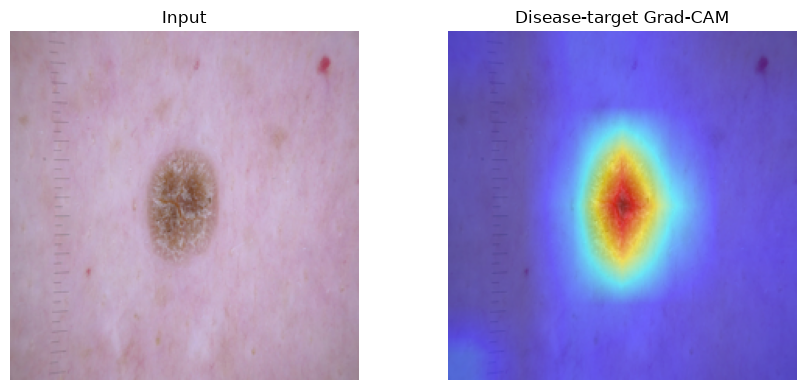

In [ ]:
import importlib.util
import sys
from pathlib import Path

root = Path(r'C:\clg\skin_pipeline_artifacts\pretrained_candidates')
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Resume the new-candidate continuation; do not rerun dataset downloads.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
pipeline.explain()
import matplotlib.pyplot as plt
figure, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(runtime.np.load(pipeline.run / 'gradcam_input.npy'))
axes[0].set_title('Input')
axes[1].imshow(runtime.Image.open(pipeline.run / 'gradcam_overlay.png'))
axes[1].set_title('Disease-target Grad-CAM')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()

Displaying the saved Gemini report; no API call or retraining needed.


MC-Dropout confidence,85.44%
Normalized predictive entropy,0.2920
Review threshold,Entropy > 0.4000
Research head output,Grade 4 / ACNE04
MC-Dropout confidence,75.78%
Normalized predictive entropy,0.5548

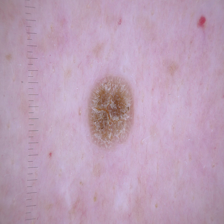
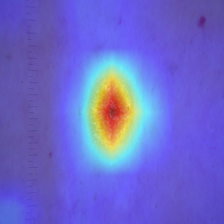

<IPython.core.display.JSON object>

Readable report: C:\clg\skin_pipeline_artifacts\pretrained_candidates\full\report.html
Structured report: C:\clg\skin_pipeline_artifacts\pretrained_candidates\full\report.json


In [30]:
import base64
import html
import importlib.util
import io
import os
import sys
from pathlib import Path
from IPython.display import HTML, JSON, display

RUN_GEMINI_REPORT = True
REGENERATE_REPORT = False
GEMINI_REPORT_MODEL = 'gemini-3.8-flash'
root = Path(r'C:\clg\skin_pipeline_artifacts\pretrained_candidates')
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run the new-candidate continuation, not dataset download cells.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)


class ReportPipeline(runtime.Pipeline):
    def gemini(self):
        import google.generativeai as genai
        if sys.platform == 'win32':
            import truststore
            truststore.inject_into_ssl()
        payload = runtime.read_json(self.run / 'payload.json', 'Run the explanation cell using the saved new checkpoint')
        self.validate_payload(payload)
        key = os.environ.get('GEMINI_API_KEY')
        if not key:
            raise RuntimeError('Missing GEMINI_API_KEY; obtain at https://aistudio.google.com/apikey and enter privately in the credential cell. Then rerun only this reporting cell.')
        genai.configure(api_key=key, transport='rest')
        policy = 'You are a fact-only formatter, never a diagnostician. Receive structured model facts only, never an image. Add no diagnosis, findings, treatment, reassurance, or severity interpretation. Return JSON with exactly source_facts (copy the whole input verbatim), specialist_review_required (copy the input boolean), and sentences (copy the six template strings exactly). Specialist review is mandatory if either normalized_entropy exceeds 0.4 or acne severity is inapplicable. Never present an inapplicable acne grade as valid. Template strings: ' + runtime.json.dumps(self.report_lines(payload))
        model = genai.GenerativeModel(GEMINI_REPORT_MODEL, system_instruction=policy)
        try:
            response = model.generate_content(runtime.json.dumps(payload, allow_nan=False), generation_config={'temperature': 0, 'response_mime_type': 'application/json', 'max_output_tokens': 4096}, request_options={'timeout': 60, 'retry': None})
            report = runtime.json.loads(response.text)
            checks = self.validate_report(report, payload)
        except Exception as error:
            raise RuntimeError(f'Gemini report not accepted ({type(error).__name__}). Verify {GEMINI_REPORT_MODEL} availability and account quota. No fabricated report is used; no automatic nested retries.') from error
        runtime.write_json(self.run / 'report.json', report)
        runtime.write_json(self.run / 'faithfulness.json', checks)
        runtime.write_json(self.run / 'gemini_audit.json', {'model': GEMINI_REPORT_MODEL, 'sdk': 'google-generativeai', 'transport': 'rest', 'image_sent': False, 'prompt_sha256': runtime.hashlib.sha256(policy.encode()).hexdigest(), 'payload_sha256': runtime.hashlib.sha256(runtime.json.dumps(payload, sort_keys=True).encode()).hexdigest()})
        runtime.write_json(self.run / 'report_status.json', {'status': 'generated_and_validated', 'model': GEMINI_REPORT_MODEL, 'api_called_in_this_cell': True, 'faithfulness_passed': True, 'expert_review': 'pending'})
        return report


def render_case_report(report, pipeline, formatter):
    facts = report['source_facts']
    pipeline.validate_payload(facts)
    pipeline.validate_report(report, facts)
    selection = runtime.read_json(pipeline.run / 'selection.json', 'Restore the saved model selection')
    input_path = pipeline.run / 'gradcam_input.npy'
    overlay_path = pipeline.run / 'gradcam_overlay.png'
    if not input_path.exists() or not overlay_path.exists():
        raise RuntimeError('Missing saved input image or Grad-CAM overlay. Run only the explanation cell; no training or downloads are needed.')
    pixels = runtime.np.load(input_path, allow_pickle=False)
    if pixels.ndim != 3 or pixels.shape[2] != 3 or not runtime.np.isfinite(pixels).all() or pixels.min() < 0 or pixels.max() > 1:
        raise ValueError('Saved report input must be finite RGB pixels in [0,1].')
    source_path = pipeline.cfg['report_image']
    if source_path is None:
        manifest = pipeline.run / 'manifests' / (facts['disease']['source_dataset'] + '_test.csv')
        frame = runtime.pd.read_csv(manifest, dtype=str)
        matches = frame[frame['sha256'].str[:16].eq(facts['case_id'])]
        if matches.empty:
            raise ValueError('Report case does not match any saved test image; regenerate explanation for the intended case.')
        source_path = matches.iloc[0]['path']
    source_path = Path(source_path)
    if not source_path.is_file() or runtime.hashlib.sha256(source_path.read_bytes()).hexdigest()[:16] != facts['case_id']:
        raise ValueError('Source image identity does not match the saved report case.')
    with runtime.Image.open(source_path) as source_image:
        expected = runtime.np.asarray(source_image.convert('RGB').resize((pixels.shape[1], pixels.shape[0])), dtype=runtime.np.float32) / 255
    if not runtime.np.array_equal(pixels, expected):
        raise ValueError('Saved processed image does not match the report source; run only the explanation cell.')
    with runtime.Image.open(overlay_path) as overlay_image:
        if overlay_image.size != (pixels.shape[1], pixels.shape[0]):
            raise ValueError('Grad-CAM overlay and processed input have different dimensions.')
    buffer = io.BytesIO()
    runtime.Image.fromarray(runtime.np.rint(pixels * 255).astype(runtime.np.uint8)).save(buffer, format='PNG')
    input_uri = 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode('ascii')
    overlay_uri = 'data:image/png;base64,' + base64.b64encode(overlay_path.read_bytes()).decode('ascii')
    disease, severity = facts['disease'], facts['severity']
    escape = lambda value: html.escape(str(value), quote=True)
    model_names = {'lcnet_100.ra2_in1k': 'LCNet-1.0', 'mobilenetv3_large_100.ra_in1k': 'MobileNetV3-Large', 'mobilenetv4_conv_small.e2400_r224_in1k': 'MobileNetV4-Conv-Small'}
    model_name = model_names.get(selection['model'], selection['model']) + ' + CBAM / dual head'
    review_text = 'Specialist review required' if facts['specialist_review_required'] else 'No entropy-threshold escalation'
    review_class = 'needs-review' if facts['specialist_review_required'] else 'within-threshold'
    review_reasons = ''.join('<li>' + escape(reason) + '</li>' for reason in facts['review_reasons'])
    reasons_html = '<ul>' + review_reasons + '</ul>' if review_reasons else '<p>Clinical validation is still required.</p>'
    disease_title = disease['class'].replace('_', ' ').capitalize()
    severity_title = 'Not clinically applicable' if not severity['applicable'] else 'ACNE04 grade ' + str(severity['predicted_grade'])
    narrative = ''.join('<p>' + escape(sentence) + '</p>' for sentence in report['sentences'])
    source_json = escape(runtime.json.dumps(facts, indent=2, allow_nan=False))
    styles = '''
.skin-report{--ink:#202722;--muted:#59645d;--line:#dce2de;--accent:#18694f;--warn:#96352d;color:var(--ink);background:#fff;font-family:"Trebuchet MS",Verdana,sans-serif;font-size:15px;line-height:1.55;max-width:1060px;margin:24px auto;padding:0 28px;box-sizing:border-box;letter-spacing:0}
.skin-report *{box-sizing:border-box;letter-spacing:0}
.skin-report h1,.skin-report h2,.skin-report h3{font-family:Georgia,serif;color:var(--ink);line-height:1.2;margin:0 0 12px}
.skin-report h1{font-size:30px}.skin-report h2{font-size:22px}.skin-report h3{font-size:19px}
.skin-report .kicker{font-size:12px;color:var(--accent);font-weight:bold;text-transform:uppercase;margin:0 0 8px}
.skin-report .subtitle,.skin-report .muted{color:var(--muted)}
.skin-report header{padding-bottom:20px;border-bottom:2px solid var(--ink)}
.skin-report .case-meta{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:14px;margin:20px 0}
.skin-report dt{font-size:12px;color:var(--muted);text-transform:uppercase}.skin-report dd{margin:4px 0 0;font-weight:bold;overflow-wrap:anywhere}
.skin-report .review{padding:16px 18px;margin:20px 0;border-left:4px solid var(--warn);background:#fcf0ee}.skin-report .review.within-threshold{border-color:var(--accent);background:#eff7f2}
.skin-report .review strong{font-size:18px}.skin-report ul{padding-left:20px;margin:8px 0 0}
.skin-report section{padding:24px 0;border-top:1px solid var(--line)}
.skin-report .media-grid,.skin-report .results-grid{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:24px}
.skin-report figure{margin:0;min-width:0}.skin-report figure img{display:block;width:100%;max-width:400px;aspect-ratio:1;object-fit:contain;border:1px solid var(--line);border-radius:6px;background:#f4f6f4}
.skin-report figcaption{font-size:13px;margin-top:8px;color:var(--muted);overflow-wrap:anywhere}
.skin-report .prediction{font-family:Georgia,serif;font-size:24px;margin:8px 0 16px;overflow-wrap:anywhere}
.skin-report .out-of-scope{color:var(--warn)}
.skin-report table{width:100%;border-collapse:collapse;font-size:14px}.skin-report th,.skin-report td{text-align:left;border-bottom:1px solid var(--line);padding:10px 0;vertical-align:top;overflow-wrap:anywhere}
.skin-report th{font-weight:normal;color:var(--muted);width:58%}.skin-report td{font-variant-numeric:tabular-nums;font-weight:bold}
.skin-report .note{font-size:13px;color:var(--muted);margin:12px 0 0}.skin-report footer{padding:18px 0;border-top:2px solid var(--ink);font-size:13px;color:var(--muted)}
.skin-report details{margin:16px 0}.skin-report summary{cursor:pointer;font-weight:bold}.skin-report pre{font-size:12px;white-space:pre-wrap;overflow-wrap:anywhere;padding:16px;background:#f4f6f4;max-height:420px;overflow:auto}
@media(max-width:640px){.skin-report{margin:16px auto;padding:0 16px}.skin-report h1{font-size:26px}.skin-report .media-grid,.skin-report .results-grid,.skin-report .case-meta{grid-template-columns:1fr}.skin-report figure img{max-width:100%}}
@media print{.skin-report{margin:0;max-width:none;padding:0;font-size:12px}.skin-report figure img{max-width:280px}.skin-report section,.skin-report figure{break-inside:avoid}.skin-report details{display:none}}
'''
    content = f'''<main class="skin-report">
<header><p class="kicker">Research case / {escape(facts['case_id'])}</p><h1>Skin Image Research Report</h1><p class="subtitle">Model prediction and attribution, not a clinician-authored diagnosis.</p></header>
<dl class="case-meta"><div><dt>Vision model</dt><dd>{escape(model_name)}</dd></div><div><dt>Image source</dt><dd>{escape(disease['source_dataset'])}</dd></div><div><dt>Report formatter</dt><dd>{escape(formatter)}</dd></div></dl>
<div class="review {review_class}"><strong>{escape(review_text)}</strong>{reasons_html}</div>
<section aria-labelledby="image-heading"><h2 id="image-heading">Image and Visual Evidence</h2><div class="media-grid">
<figure><img src="{input_uri}" alt="Actual processed skin image for this report" width="{pixels.shape[1]}" height="{pixels.shape[0]}"><figcaption><strong>Processed input</strong> / {escape(source_path.name)} / {pixels.shape[1]} x {pixels.shape[0]} pixels</figcaption></figure>
<figure><img src="{overlay_uri}" alt="Disease-target Grad-CAM overlay for the same input image" width="{pixels.shape[1]}" height="{pixels.shape[0]}"><figcaption><strong>Disease-target Grad-CAM</strong> / contribution to the predicted class, not a lesion mask</figcaption></figure>
</div><p class="note">Images are embedded locally in this page. Gemini received the structured facts only, not either image.</p></section>
<section aria-labelledby="results-heading"><h2 id="results-heading">Prediction and Uncertainty</h2><div class="results-grid">
<div><h3>Disease classification</h3><p class="prediction">{escape(disease_title)}</p><table><tbody><tr><th>MC-Dropout confidence</th><td>{disease['confidence'] * 100:.2f}%</td></tr><tr><th>Normalized predictive entropy</th><td>{disease['normalized_entropy']:.4f}</td></tr><tr><th>Review threshold</th><td>Entropy &gt; 0.4000</td></tr></tbody></table><p class="note">Confidence is uncalibrated model output, not the probability of a correct clinical diagnosis.</p></div>
<div><h3>Acne-severity head</h3><p class="prediction out-of-scope">{escape(severity_title)}</p><table><tbody><tr><th>Research head output</th><td>Grade {severity['predicted_grade']} / ACNE04</td></tr><tr><th>MC-Dropout confidence</th><td>{severity['confidence'] * 100:.2f}%</td></tr><tr><th>Normalized predictive entropy</th><td>{severity['normalized_entropy']:.4f}</td></tr></tbody></table><p class="note">{escape(severity['status'])}</p></div>
</div></section>
<section><h2>Attribution Note</h2><p>{escape(facts['gradcam_evidence'])}</p></section>
<section><h2>Verified Gemini Narrative</h2>{narrative}<p class="note">Source-faithfulness passed. Gemini narrated the supplied outputs; it did not independently assess the image.</p><details><summary>Structured source facts</summary><pre>{source_json}</pre></details></section>
<footer>Research-only output. Clinical correctness and report suitability require specialist assessment. Expert review remains pending.</footer>
</main>'''
    return '<style>' + styles + '</style>' + content


pipeline = ReportPipeline(root)
if RUN_GEMINI_REPORT:
    report = None
    report_file = pipeline.run / 'report.json'
    audit_file = pipeline.run / 'gemini_audit.json'
    current_payload = runtime.read_json(pipeline.run / 'payload.json', 'Run the explanation cell')
    pipeline.validate_payload(current_payload)
    if not REGENERATE_REPORT and report_file.exists() and audit_file.exists():
        try:
            cached_report = runtime.read_json(report_file, 'Generate a report')
            audit = runtime.read_json(audit_file, 'Generate a report')
            pipeline.validate_report(cached_report, current_payload)
            if audit['model'] == GEMINI_REPORT_MODEL:
                report = cached_report
                print('Displaying the saved Gemini report; no API call or retraining needed.')
        except (ValueError, KeyError):
            print('Saved report no longer matches the source facts; generating a newly validated report.')
    if report is None:
        report = pipeline.gemini()
    report_html = render_case_report(report, pipeline, GEMINI_REPORT_MODEL)
    report_path = pipeline.run / 'report.html'
    report_path.write_text('<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Skin Image Research Report</title></head><body>' + report_html + '</body></html>', encoding='utf-8')
    display(HTML(report_html))
    display(JSON(report, expanded=False))
    print('Readable report:', report_path)
    print('Structured report:', report_file)
else:
    print('Report generation/display is disabled. Set RUN_GEMINI_REPORT=True to show the report without retraining.')

In [28]:
import importlib.util
import sys
from pathlib import Path

root = Path(r'C:\clg\skin_pipeline_artifacts\pretrained_candidates')
module_path = root / 'skin_pipeline_runtime.py'
if not module_path.exists():
    raise RuntimeError(f'Missing {module_path}. Run the new-candidate continuation; dataset downloading is not needed.')
spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
runtime = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = runtime
spec.loader.exec_module(runtime)
pipeline = runtime.Pipeline(root)
payload = runtime.read_json(pipeline.run / 'payload.json', 'Run the explanation stage')
pipeline.validate_payload(payload)
print('Structured source payload validation: PASS. This is not report-quality evaluation.')
if (pipeline.run / 'report.json').exists():
    pipeline.expert_review()
else:
    status = runtime.read_json(pipeline.run / 'report_status.json', 'Run the reporting-status cell')
    print('Report faithfulness evaluation: NOT PERFORMED; no Gemini report exists.')
    print('Expert-reviewed report sample: PENDING; no reviews or acceptance scores are fabricated.')
    print('Reporting status:', status['status'])

Structured source payload validation: PASS. This is not report-quality evaluation.
Faithfulness: {'faithfulness_passed': True, 'method': 'Exact source JSON equality, review-policy equality, closed sentence-template equality. This checks faithfulness, not medical correctness.'}
Expert review: 0 completed reviews; target 10 distinct cases. Blank rows are not evidence. Template: C:\clg\skin_pipeline_artifacts\pretrained_candidates\full\expert_review.csv


In [29]:
def run_pipeline(execute=False):
    import importlib.util
    import sys
    from pathlib import Path

    root = Path(r'C:\clg\skin_pipeline_artifacts\pretrained_candidates')
    module_path = root / 'skin_pipeline_runtime.py'
    if not module_path.exists():
        raise RuntimeError(f'Missing {module_path}. Run the new-candidate continuation; do not rerun dataset download cells.')
    if execute:
        raise RuntimeError('Full pipeline reruns are disabled for this cached continuation. Use individual remaining cells to avoid repeating datasets or training; the reporting cell can redisplay its saved report independently.')
    spec = importlib.util.spec_from_file_location('skin_pipeline_runtime', module_path)
    runtime = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = runtime
    spec.loader.exec_module(runtime)
    pipeline = runtime.Pipeline(root)
    required = ['comparison.csv', 'selection.json', 'dual_disease.pt', 'dual_final.pt', 'severity_metrics.json', 'payload.json', 'gradcam_overlay.png']
    missing = [filename for filename in required if not (pipeline.run / filename).exists()]
    if missing:
        raise RuntimeError('Vision stages are incomplete. Missing artifacts: ' + ', '.join(missing) + '. Resume the owning stage; no downloads or fabricated results are substituted.')
    payload = runtime.read_json(pipeline.run / 'payload.json', 'Run explanation')
    pipeline.validate_payload(payload)
    print('Vision training, severity transfer, uncertainty, Grad-CAM, and source JSON: COMPLETED.')
    print('Artifacts:', pipeline.run)
    comparison = runtime.pd.read_csv(pipeline.run / 'comparison.csv')
    summary = comparison[['Dataset', 'Name', 'Accuracy', 'F1', 'Params(M)']].copy()
    summary['Accuracy (%)'] = summary.pop('Accuracy') * 100
    summary['Macro F1 (%)'] = summary.pop('F1') * 100
    print(summary.to_string(index=False))
    print('The >70% accuracy target was met on HAM10000, but NOT on PAD-UFES-20 or ACNE04 severity.')
    if (pipeline.run / 'report.json').exists():
        report = runtime.read_json(pipeline.run / 'report.json', 'Run reporting')
        pipeline.validate_report(report, payload)
        print('Gemini report source-faithfulness validation: PASS; expert review still requires human reviewers.')
        print('Readable report:', pipeline.run / 'report.html')
    else:
        status = runtime.read_json(pipeline.run / 'report_status.json', 'Run reporting-status cell')
        print('Gemini report:', status['status'], '| Report quality and expert review: NOT EVALUATED.')
    return str(pipeline.run)


run_pipeline(execute=False)

Vision training, severity transfer, uncertainty, Grad-CAM, and source JSON: COMPLETED.
Artifacts: C:\clg\skin_pipeline_artifacts\pretrained_candidates\full
    Dataset                   Name  Params(M)  Accuracy (%)  Macro F1 (%)
   HAM10000      MobileNetV3-Large   4.210999     77.383924     54.499782
   HAM10000 MobileNetV4-Conv-Small   2.501991     74.987519     45.736558
   HAM10000              LCNet-1.0   1.681767     79.031453     58.840804
PAD_UFES_20      MobileNetV3-Large   4.209718     56.703297     44.394940
PAD_UFES_20 MobileNetV4-Conv-Small   2.500710     53.186813     39.553610
PAD_UFES_20              LCNet-1.0   1.680486     55.384615     43.806938
The >70% accuracy target was met on HAM10000, but NOT on PAD-UFES-20 or ACNE04 severity.
Gemini report source-faithfulness validation: PASS; expert review still requires human reviewers.
Readable report: C:\clg\skin_pipeline_artifacts\pretrained_candidates\full\report.html


'C:\\clg\\skin_pipeline_artifacts\\pretrained_candidates\\full'